# E-Commerce Logistics & Delivery Performance Analytics
### Expected Delivery Date (EDD) Prediction, SLA Breach Analysis & Multi-Carrier Optimization

## About the Project

This project focuses on analyzing e-commerce shipment and delivery operations across six major Indian logistics carriers: Blue Dart, Delhivery, Ekart, XpressBees, Ecom Express, and Shadowfax.

Using a dataset of 25,000 shipment records, the objective is to evaluate delivery performance, identify factors contributing to shipment delays, predict Expected Delivery Dates (EDD), and optimize courier selection based on delivery speed and shipping costs.

The project involves data cleaning, exploratory data analysis (EDA), SQL-based business analysis, and machine learning techniques to solve real-world logistics challenges.

### Key Objectives

1. **Exploratory Data Analysis:** Understand shipment patterns, carrier performance, delivery zones, and operational factors.
2. **Delivery Time Prediction:** Develop regression models to predict shipment transit time and estimate delivery dates.
3. **SLA Breach Prediction:** Build classification models to identify shipments at risk of missing promised delivery timelines.
4. **Carrier Performance Analysis:** Compare logistics partners based on delivery speed, shipping costs, and SLA compliance.
5. **Courier Recommendation:** Identify cost-effective carriers that meet promised delivery timelines.
6. **Business Intelligence:** Develop interactive Power BI dashboards to communicate insights and support logistics decision-making.

### Technology Stack

* Python (Pandas, NumPy)
* Data Visualization (Matplotlib, Seaborn)
* SQL (PostgreSQL)
* Machine Learning (Scikit-learn, XGBoost)
* Business Intelligence (Power BI)
* Jupyter Notebook


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("darkgrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100
from datetime import datetime, timedelta
from scipy import stats
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV
)
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    OneHotEncoder,
    LabelEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)
from imblearn.over_sampling import SMOTE
from xgboost import XGBRegressor, XGBClassifier
from sqlalchemy import create_engine
import warnings
warnings.filterwarnings('ignore')
print("All required libraries imported successfully!")

All required libraries imported successfully!


In [2]:
df = pd.read_csv(r"C:\Users\papus\OneDrive\Documents\SupplyChain & Logistics Project\india_multi_agency_edd_dataset.csv")
df.head()

,Order_ID,Delivery_Partner,Origin_City,Origin_Pincode,Destination_City,Destination_Pincode,Logistics_Zone,Distance_km,Shipment_Mode,Weight_kg,...,Festival_Peak,Order_Timestamp,Dispatch_Timestamp,Pickup_Delay_Hours,Transit_Time_Hours,SLA_Promised_Days,Expected_Delivery_Timestamp,Expected_Delivery_Date,Actual_Delivery_Days,Is_Delayed_SLA
0,IND2026000000,XpressBees,Kolkata,700012,Kolkata,705044,Zone B (Within State/Region),53.5,Surface,0.13,...,1,05-03-2026 03:00,05-03-2026 08:18,5.3,55.4,2,07-03-2026 15:42,07-03-2026,3,1
1,IND2026000001,Ecom Express,Chennai,600022,Kolkata,700087,Zone C (Metro-to-Metro),1497.5,Surface,2.40,...,0,10-03-2026 08:00,10-03-2026 11:24,3.4,85.3,3,14-03-2026 00:42,14-03-2026,4,1
2,IND2026000002,Ekart,Mumbai,400055,Jaipur,316042,Zone D (Rest of India),941.3,Surface,0.31,...,0,23-09-2026 04:00,23-09-2026 10:54,6.9,52.4,5,25-09-2026 15:18,25-09-2026,3,0
3,IND2026000003,Ecom Express,Chennai,600088,Chennai,605080,Zone B (Within State/Region),193.4,Surface,0.86,...,0,01-06-2026 12:00,01-06-2026 18:42,6.7,16.9,2,02-06-2026 11:36,02-06-2026,1,0
4,IND2026000004,Ecom Express,Kolkata,700076,Kolkata,707050,Zone B (Within State/Region),349.8,Surface,0.42,...,0,19-01-2026 05:00,19-01-2026 11:00,6.0,37.2,2,21-01-2026 00:12,21-01-2026,2,0


In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (25000, 23)


In [4]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['Order_ID', 'Delivery_Partner', 'Origin_City', 'Origin_Pincode', 'Destination_City', 'Destination_Pincode', 'Logistics_Zone', 'Distance_km', 'Shipment_Mode', 'Weight_kg', 'Is_COD', 'Shipping_Cost_INR', 'Weather_Condition', 'Festival_Peak', 'Order_Timestamp', 'Dispatch_Timestamp', 'Pickup_Delay_Hours', 'Transit_Time_Hours', 'SLA_Promised_Days', 'Expected_Delivery_Timestamp', 'Expected_Delivery_Date', 'Actual_Delivery_Days', 'Is_Delayed_SLA']


In [5]:
df.columns = df.columns.str.strip()

In [6]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['Order_ID', 'Delivery_Partner', 'Origin_City', 'Origin_Pincode', 'Destination_City', 'Destination_Pincode', 'Logistics_Zone', 'Distance_km', 'Shipment_Mode', 'Weight_kg', 'Is_COD', 'Shipping_Cost_INR', 'Weather_Condition', 'Festival_Peak', 'Order_Timestamp', 'Dispatch_Timestamp', 'Pickup_Delay_Hours', 'Transit_Time_Hours', 'SLA_Promised_Days', 'Expected_Delivery_Timestamp', 'Expected_Delivery_Date', 'Actual_Delivery_Days', 'Is_Delayed_SLA']


In [8]:
df.dtypes

Order_ID                        object
Delivery_Partner                object
Origin_City                     object
Origin_Pincode                   int64
Destination_City                object
Destination_Pincode              int64
Logistics_Zone                  object
Distance_km                    float64
Shipment_Mode                   object
Weight_kg                      float64
Is_COD                           int64
Shipping_Cost_INR              float64
Weather_Condition               object
Festival_Peak                    int64
Order_Timestamp                 object
Dispatch_Timestamp              object
Pickup_Delay_Hours             float64
Transit_Time_Hours             float64
SLA_Promised_Days                int64
Expected_Delivery_Timestamp     object
Expected_Delivery_Date          object
Actual_Delivery_Days             int64
Is_Delayed_SLA                   int64
dtype: object

In [10]:
# Converting columns to datetime
for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors='coerce')

print(df[date_columns].dtypes)

Order_Timestamp                datetime64[ns]
Dispatch_Timestamp             datetime64[ns]
Expected_Delivery_Timestamp    datetime64[ns]
Expected_Delivery_Date         datetime64[ns]
dtype: object


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   Order_ID                     25000 non-null  object        
 1   Delivery_Partner             25000 non-null  object        
 2   Origin_City                  25000 non-null  object        
 3   Origin_Pincode               25000 non-null  int64         
 4   Destination_City             25000 non-null  object        
 5   Destination_Pincode          25000 non-null  int64         
 6   Logistics_Zone               25000 non-null  object        
 7   Distance_km                  25000 non-null  float64       
 8   Shipment_Mode                25000 non-null  object        
 9   Weight_kg                    25000 non-null  float64       
 10  Is_COD                       25000 non-null  int64         
 11  Shipping_Cost_INR            25000 non-nu

In [12]:
df.describe()

,Origin_Pincode,Destination_Pincode,Distance_km,Weight_kg,Is_COD,Shipping_Cost_INR,Festival_Peak,Order_Timestamp,Dispatch_Timestamp,Pickup_Delay_Hours,Transit_Time_Hours,SLA_Promised_Days,Expected_Delivery_Timestamp,Expected_Delivery_Date,Actual_Delivery_Days,Is_Delayed_SLA
count,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,10111,10097,25000.000000,25000.000000,25000.000000,9886,9886,25000.000000,25000.000000
mean,458396.390320,442599.591280,781.681916,2.235244,0.397520,142.968268,0.147800,2026-06-20 21:56:57.347443456,2026-06-21 11:56:42.404674560,9.393460,43.943500,2.988960,2026-06-24 09:51:07.865668608,2026-06-23 22:04:46.951244032,2.718480,0.255200
min,110001.000000,110001.000000,2.000000,0.100000,0.000000,36.900000,0.000000,2026-01-01 00:00:00,2026-01-01 02:12:00,2.000000,4.000000,1.000000,2026-01-01 09:00:00,2026-01-01 00:00:00,1.000000,0.000000
25%,380098.000000,326095.750000,129.375000,0.640000,0.000000,94.220000,0.000000,2026-04-01 06:30:00,2026-04-01 13:42:00,4.300000,23.500000,2.000000,2026-04-02 21:37:30,2026-04-02 00:00:00,2.000000,0.000000
50%,500005.000000,417056.500000,609.750000,1.530000,0.000000,129.460000,0.000000,2026-07-01 06:00:00,2026-07-01 14:18:00,6.500000,39.000000,2.000000,2026-07-02 14:42:00,2026-07-02 00:00:00,3.000000,0.000000
75%,600003.000000,570052.250000,1341.925000,3.070000,1.000000,175.260000,0.000000,2026-09-09 05:30:00,2026-09-09 11:00:00,16.100000,59.100000,5.000000,2026-10-01 00:57:00,2026-10-01 00:00:00,3.000000,1.000000
max,700098.000000,781098.000000,2799.800000,23.720000,1.000000,814.960000,1.000000,2026-12-09 23:00:00,2026-12-09 21:54:00,22.000000,191.300000,7.000000,2026-12-09 23:54:00,2026-12-09 00:00:00,9.000000,1.000000
std,168225.489276,180276.888537,695.938580,2.234083,0.489395,69.389404,0.354909,NaN,NaN,6.459602,26.551341,1.734635,NaN,NaN,1.180713,0.435982


### Checking missing values in each column

In [13]:

df.isnull().sum()

Order_ID                           0
Delivery_Partner                   0
Origin_City                        0
Origin_Pincode                     0
Destination_City                   0
Destination_Pincode                0
Logistics_Zone                     0
Distance_km                        0
Shipment_Mode                      0
Weight_kg                          0
Is_COD                             0
Shipping_Cost_INR                  0
Weather_Condition                  0
Festival_Peak                      0
Order_Timestamp                14889
Dispatch_Timestamp             14903
Pickup_Delay_Hours                 0
Transit_Time_Hours                 0
SLA_Promised_Days                  0
Expected_Delivery_Timestamp    15114
Expected_Delivery_Date         15114
Actual_Delivery_Days               0
Is_Delayed_SLA                     0
dtype: int64

In [14]:
date_columns = [
    'Order_Timestamp',
    'Dispatch_Timestamp',
    'Expected_Delivery_Timestamp',
    'Expected_Delivery_Date'
]

raw_dates = pd.read_csv(
    r"C:\Users\papus\OneDrive\Documents\SupplyChain & Logistics Project\india_multi_agency_edd_dataset.csv",
    usecols=date_columns
)
raw_dates.head(10)

,Order_Timestamp,Dispatch_Timestamp,Expected_Delivery_Timestamp,Expected_Delivery_Date
0,05-03-2026 03:00,05-03-2026 08:18,07-03-2026 15:42,07-03-2026
1,10-03-2026 08:00,10-03-2026 11:24,14-03-2026 00:42,14-03-2026
2,23-09-2026 04:00,23-09-2026 10:54,25-09-2026 15:18,25-09-2026
3,01-06-2026 12:00,01-06-2026 18:42,02-06-2026 11:36,02-06-2026
4,19-01-2026 05:00,19-01-2026 11:00,21-01-2026 00:12,21-01-2026
5,10-04-2026 22:00,11-04-2026 14:42,13-04-2026 21:42,13-04-2026
6,24-03-2026 01:00,24-03-2026 03:54,27-03-2026 11:36,27-03-2026
7,28-03-2026 13:00,28-03-2026 16:24,28-03-2026 21:42,28-03-2026
8,10-05-2026 10:00,10-05-2026 14:00,13-05-2026 19:30,13-05-2026
9,04-06-2026 12:00,04-06-2026 16:06,07-06-2026 11:48,07-06-2026


In [15]:
date_columns = [
    'Order_Timestamp',
    'Dispatch_Timestamp',
    'Expected_Delivery_Timestamp'
]

for col in date_columns:
    df[col] = pd.to_datetime(
        df[col],
        format='%d-%m-%Y %H:%M',
        errors='coerce'
    )

df['Expected_Delivery_Date'] = pd.to_datetime(
    df['Expected_Delivery_Date'],
    format='%d-%m-%Y',
    errors='coerce'
)

In [16]:
df[date_columns + ['Expected_Delivery_Date']].isnull().sum()

Order_Timestamp                14889
Dispatch_Timestamp             14903
Expected_Delivery_Timestamp    15114
Expected_Delivery_Date         15114
dtype: int64

In [17]:
for col in date_columns:
    print(f"\n{col}")
    print("Data Type:", raw_dates[col].dtype)
    print("Sample Values:")
    print(raw_dates[col].head(5).tolist())
    print("Missing in Original:", raw_dates[col].isnull().sum())


Order_Timestamp
Data Type: object
Sample Values:
['05-03-2026 03:00', '10-03-2026 08:00', '23-09-2026 04:00', '01-06-2026 12:00', '19-01-2026 05:00']
Missing in Original: 0

Dispatch_Timestamp
Data Type: object
Sample Values:
['05-03-2026 08:18', '10-03-2026 11:24', '23-09-2026 10:54', '01-06-2026 18:42', '19-01-2026 11:00']
Missing in Original: 0

Expected_Delivery_Timestamp
Data Type: object
Sample Values:
['07-03-2026 15:42', '14-03-2026 00:42', '25-09-2026 15:18', '02-06-2026 11:36', '21-01-2026 00:12']
Missing in Original: 0


In [18]:
for col in date_columns:
    converted = pd.to_datetime(
        raw_dates[col].str.strip(),
        format='%d-%m-%Y %H:%M',
        errors='coerce'
    )

    failed = raw_dates.loc[converted.isna(), col]

    print(f"\n{col}")
    print("Failed conversions:", failed.shape[0])
    print("Failed values:")
    print(failed.head(10).tolist())


Order_Timestamp
Failed conversions: 0
Failed values:
[]

Dispatch_Timestamp
Failed conversions: 0
Failed values:
[]

Expected_Delivery_Timestamp
Failed conversions: 0
Failed values:
[]


In [19]:
for col in date_columns:
    df[col] = pd.to_datetime(
        raw_dates[col].str.strip(),
        format='%d-%m-%Y %H:%M',
        errors='coerce'
    )

df['Expected_Delivery_Date'] = pd.to_datetime(
    raw_dates['Expected_Delivery_Date'].str.strip(),
    format='%d-%m-%Y',
    errors='coerce'
)

In [20]:
df[date_columns + ['Expected_Delivery_Date']].isnull().sum()

Order_Timestamp                0
Dispatch_Timestamp             0
Expected_Delivery_Timestamp    0
Expected_Delivery_Date         0
dtype: int64

In [21]:
df[date_columns + ['Expected_Delivery_Date']].dtypes

Order_Timestamp                datetime64[ns]
Dispatch_Timestamp             datetime64[ns]
Expected_Delivery_Timestamp    datetime64[ns]
Expected_Delivery_Date         datetime64[ns]
dtype: object

In [25]:
df.isnull().sum()

Order_ID                       0
Delivery_Partner               0
Origin_City                    0
Origin_Pincode                 0
Destination_City               0
Destination_Pincode            0
Logistics_Zone                 0
Distance_km                    0
Shipment_Mode                  0
Weight_kg                      0
Is_COD                         0
Shipping_Cost_INR              0
Weather_Condition              0
Festival_Peak                  0
Order_Timestamp                0
Dispatch_Timestamp             0
Pickup_Delay_Hours             0
Transit_Time_Hours             0
SLA_Promised_Days              0
Expected_Delivery_Timestamp    0
Expected_Delivery_Date         0
Actual_Delivery_Days           0
Is_Delayed_SLA                 0
dtype: int64

### Checking duplicate values

In [22]:
df.duplicated().sum()

np.int64(0)

In [23]:
df['Order_ID'].duplicated().sum()

np.int64(0)

### Outlier Detection

In [26]:
# Selecting numerical columns
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

print("Numerical Columns:")
print(numerical_cols)

Numerical Columns:
['Origin_Pincode', 'Destination_Pincode', 'Distance_km', 'Weight_kg', 'Is_COD', 'Shipping_Cost_INR', 'Festival_Peak', 'Pickup_Delay_Hours', 'Transit_Time_Hours', 'SLA_Promised_Days', 'Actual_Delivery_Days', 'Is_Delayed_SLA']


In [27]:
outlier_cols = [
    'Distance_km',
    'Weight_kg',
    'Shipping_Cost_INR',
    'Pickup_Delay_Hours',
    'Transit_Time_Hours',
    'SLA_Promised_Days',
    'Actual_Delivery_Days'
]

In [28]:
for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col}: {len(outliers)} outliers")

Distance_km: 0 outliers
Weight_kg: 1246 outliers
Shipping_Cost_INR: 877 outliers
Pickup_Delay_Hours: 0 outliers
Transit_Time_Hours: 461 outliers
SLA_Promised_Days: 0 outliers
Actual_Delivery_Days: 2019 outliers


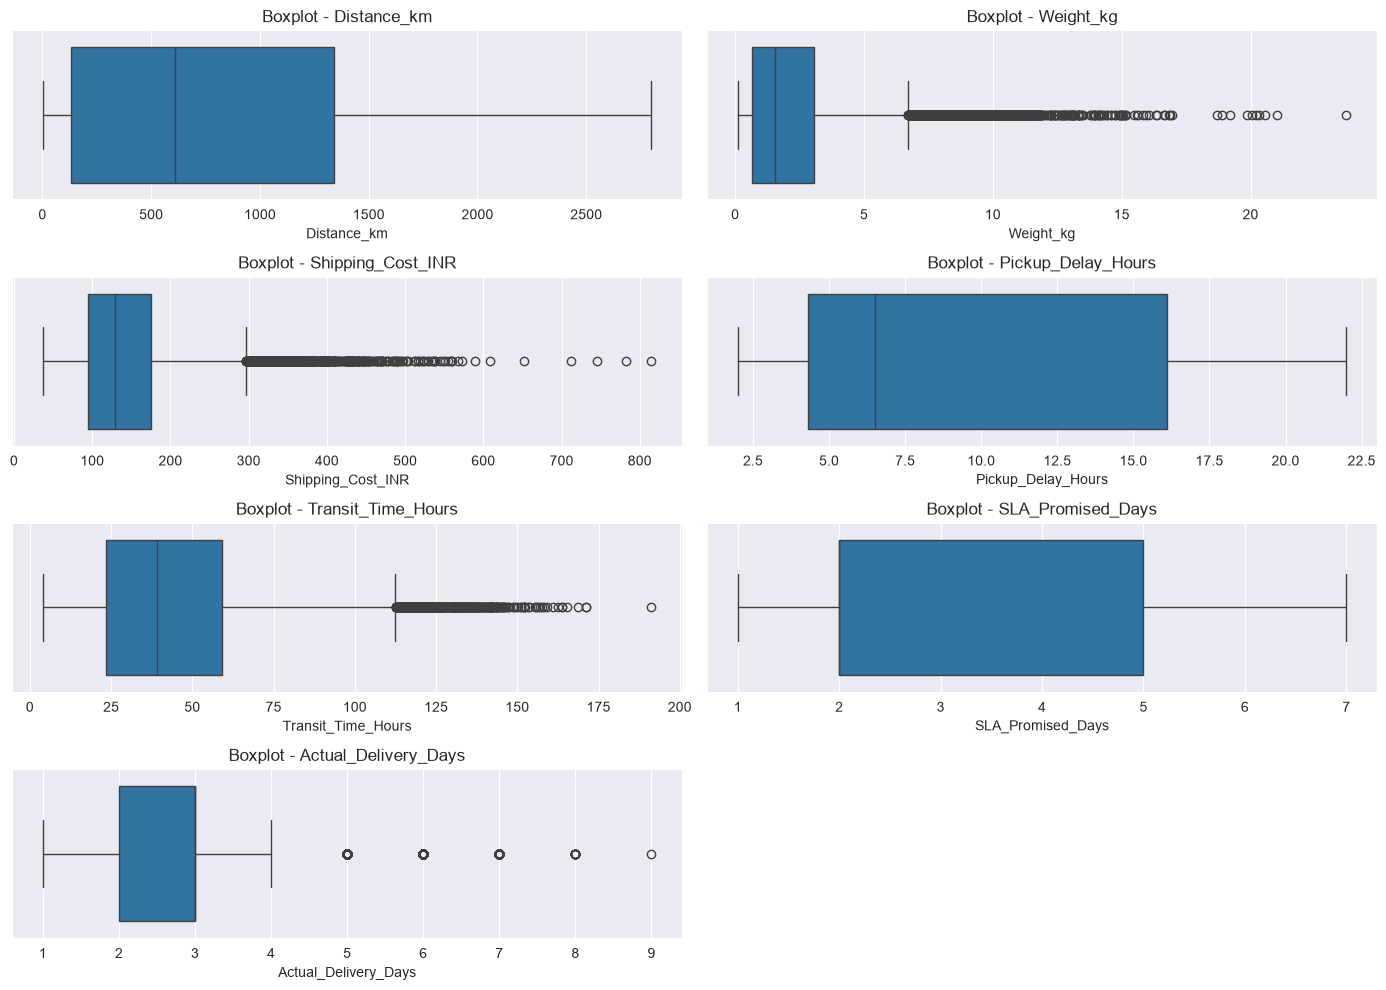

In [29]:
plt.figure(figsize=(14, 10))

for i, col in enumerate(outlier_cols, 1):
    plt.subplot(4, 2, i)
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot - {col}')

plt.tight_layout()
plt.show()

In [30]:
df.nlargest(10, 'Actual_Delivery_Days')[
    [
        'Order_ID',
        'Delivery_Partner',
        'Logistics_Zone',
        'Distance_km',
        'Weather_Condition',
        'Transit_Time_Hours',
        'SLA_Promised_Days',
        'Actual_Delivery_Days',
        'Is_Delayed_SLA'
    ]
]

,Order_ID,Delivery_Partner,Logistics_Zone,Distance_km,Weather_Condition,Transit_Time_Hours,SLA_Promised_Days,Actual_Delivery_Days,Is_Delayed_SLA
17183,IND2026017183,Ecom Express,Zone E (NE / J&K / Special),2798.6,Rainy,191.3,7,9,1
1190,IND2026001190,XpressBees,Zone E (NE / J&K / Special),2772.1,Rainy,163.7,7,8,1
7600,IND2026007600,Ecom Express,Zone E (NE / J&K / Special),2352.3,Monsoon Storm,155.9,7,8,1
8355,IND2026008355,Ecom Express,Zone D (Rest of India),1546.9,Fog/Smog,153.5,5,8,1
10733,IND2026010733,Ecom Express,Zone E (NE / J&K / Special),2747.2,Monsoon Storm,157.1,7,8,1
11603,IND2026011603,Ecom Express,Zone E (NE / J&K / Special),2778.3,Clear,150.3,7,8,1
12015,IND2026012015,XpressBees,Zone E (NE / J&K / Special),2541.0,Rainy,158.1,7,8,1
13116,IND2026013116,XpressBees,Zone E (NE / J&K / Special),1718.7,Rainy,165.4,7,8,1
14015,IND2026014015,Ecom Express,Zone E (NE / J&K / Special),2155.0,Fog/Smog,171.0,7,8,1
16111,IND2026016111,Ecom Express,Zone E (NE / J&K / Special),2614.2,Clear,162.6,7,8,1


In [31]:
df.nlargest(10, 'Weight_kg')[
    [
        'Order_ID',
        'Delivery_Partner',
        'Logistics_Zone',
        'Distance_km',
        'Weight_kg',
        'Shipment_Mode',
        'Shipping_Cost_INR'
    ]
]

,Order_ID,Delivery_Partner,Logistics_Zone,Distance_km,Weight_kg,Shipment_Mode,Shipping_Cost_INR
6772,IND2026006772,Blue Dart,Zone D (Rest of India),434.8,23.72,Air,814.96
21167,IND2026021167,Shadowfax,Zone C (Metro-to-Metro),538.6,21.04,Surface,470.26
4190,IND2026004190,Blue Dart,Zone B (Within State/Region),210.6,20.57,Air,744.89
12152,IND2026012152,XpressBees,Zone C (Metro-to-Metro),564.5,20.32,Surface,426.34
13340,IND2026013340,Ecom Express,Zone D (Rest of India),1901.1,20.21,Surface,479.82
12820,IND2026012820,Blue Dart,Zone D (Rest of India),1038.2,20.04,Air,782.60
12527,IND2026012527,Ecom Express,Zone B (Within State/Region),203.6,19.86,Surface,405.62
8238,IND2026008238,Ekart,Zone C (Metro-to-Metro),566.0,19.20,Surface,410.24
7529,IND2026007529,Ecom Express,Zone B (Within State/Region),109.9,18.88,Surface,384.24
18537,IND2026018537,XpressBees,Zone A (Intra-City),28.5,18.69,Surface,375.56


In [32]:
df.nlargest(10, 'Shipping_Cost_INR')[
    [
        'Order_ID',
        'Delivery_Partner',
        'Logistics_Zone',
        'Distance_km',
        'Weight_kg',
        'Shipment_Mode',
        'Shipping_Cost_INR'
    ]
]

,Order_ID,Delivery_Partner,Logistics_Zone,Distance_km,Weight_kg,Shipment_Mode,Shipping_Cost_INR
6772,IND2026006772,Blue Dart,Zone D (Rest of India),434.8,23.72,Air,814.96
12820,IND2026012820,Blue Dart,Zone D (Rest of India),1038.2,20.04,Air,782.60
4190,IND2026004190,Blue Dart,Zone B (Within State/Region),210.6,20.57,Air,744.89
9943,IND2026009943,Blue Dart,Zone C (Metro-to-Metro),1739.8,16.05,Air,712.59
22625,IND2026022625,Blue Dart,Zone E (NE / J&K / Special),2252.2,12.80,Air,651.78
12117,IND2026012117,Blue Dart,Zone D (Rest of India),2047.7,11.74,Air,608.16
9044,IND2026009044,XpressBees,Zone C (Metro-to-Metro),909.8,16.35,Air,589.91
349,IND2026000349,Blue Dart,Zone E (NE / J&K / Special),1768.9,11.14,Air,573.04
10842,IND2026010842,Ekart,Zone C (Metro-to-Metro),1546.1,13.94,Air,567.62
18675,IND2026018675,Blue Dart,Zone D (Rest of India),1630.5,11.01,Air,560.44


In [34]:
df.loc[df['Order_ID'] == 'IND2026006772'].T

,6772
Order_ID,IND2026006772
Delivery_Partner,Blue Dart
Origin_City,Delhi_NCR
Origin_Pincode,110066
Destination_City,Jaipur
Destination_Pincode,314028
Logistics_Zone,Zone D (Rest of India)
Distance_km,434.8
Shipment_Mode,Air
Weight_kg,23.72


In [35]:
df[['Shipping_Cost_INR', 'Weight_kg', 'Distance_km']].corr()

,Shipping_Cost_INR,Weight_kg,Distance_km
Shipping_Cost_INR,1.000000,0.641761,0.511253
Weight_kg,0.641761,1.000000,0.001337
Distance_km,0.511253,0.001337,1.000000


In [36]:
df.nlargest(10, 'Transit_Time_Hours')[[
    'Order_ID',
    'Delivery_Partner',
    'Logistics_Zone',
    'Distance_km',
    'Weather_Condition',
    'Shipment_Mode',
    'Transit_Time_Hours',
    'SLA_Promised_Days',
    'Actual_Delivery_Days',
    'Is_Delayed_SLA'
]]

,Order_ID,Delivery_Partner,Logistics_Zone,Distance_km,Weather_Condition,Shipment_Mode,Transit_Time_Hours,SLA_Promised_Days,Actual_Delivery_Days,Is_Delayed_SLA
17183,IND2026017183,Ecom Express,Zone E (NE / J&K / Special),2798.6,Rainy,Surface,191.3,7,9,1
20621,IND2026020621,XpressBees,Zone D (Rest of India),1556.1,Monsoon Storm,Surface,171.1,5,8,1
14015,IND2026014015,Ecom Express,Zone E (NE / J&K / Special),2155.0,Fog/Smog,Surface,171.0,7,8,1
21860,IND2026021860,Ecom Express,Zone E (NE / J&K / Special),2311.1,Clear,Surface,168.6,7,8,1
13116,IND2026013116,XpressBees,Zone E (NE / J&K / Special),1718.7,Rainy,Surface,165.4,7,8,1
20896,IND2026020896,XpressBees,Zone E (NE / J&K / Special),2455.1,Clear,Surface,163.8,7,8,1
1190,IND2026001190,XpressBees,Zone E (NE / J&K / Special),2772.1,Rainy,Surface,163.7,7,8,1
16111,IND2026016111,Ecom Express,Zone E (NE / J&K / Special),2614.2,Clear,Surface,162.6,7,8,1
13380,IND2026013380,Ecom Express,Zone E (NE / J&K / Special),2278.3,Rainy,Surface,161.1,7,7,0
22054,IND2026022054,Ecom Express,Zone E (NE / J&K / Special),2798.3,Rainy,Surface,159.0,7,7,0


In [37]:
df.nlargest(10, 'Pickup_Delay_Hours')[[
    'Order_ID',
    'Delivery_Partner',
    'Logistics_Zone',
    'Distance_km',
    'Shipment_Mode',
    'Pickup_Delay_Hours',
    'Transit_Time_Hours',
    'SLA_Promised_Days',
    'Actual_Delivery_Days',
    'Is_Delayed_SLA'
]]

,Order_ID,Delivery_Partner,Logistics_Zone,Distance_km,Shipment_Mode,Pickup_Delay_Hours,Transit_Time_Hours,SLA_Promised_Days,Actual_Delivery_Days,Is_Delayed_SLA
600,IND2026000600,Blue Dart,Zone A (Intra-City),19.6,Surface,22.0,16.8,1,2,1
682,IND2026000682,Shadowfax,Zone C (Metro-to-Metro),1016.6,Surface,22.0,32.3,3,3,0
1382,IND2026001382,Ekart,Zone C (Metro-to-Metro),1611.9,Surface,22.0,48.0,3,3,0
2411,IND2026002411,Ekart,Zone C (Metro-to-Metro),1309.6,Surface,22.0,41.0,3,3,0
2589,IND2026002589,XpressBees,Zone E (NE / J&K / Special),1524.8,Air,22.0,71.9,6,4,0
2838,IND2026002838,Ecom Express,Zone B (Within State/Region),356.1,Surface,22.0,24.9,2,2,0
3151,IND2026003151,XpressBees,Zone D (Rest of India),801.6,Surface,22.0,48.4,5,3,0
3396,IND2026003396,Shadowfax,Zone E (NE / J&K / Special),1102.7,Surface,22.0,70.9,7,4,0
3957,IND2026003957,XpressBees,Zone C (Metro-to-Metro),1099.1,Air,22.0,63.5,2,4,1
4348,IND2026004348,Delhivery,Zone B (Within State/Region),198.5,Air,22.0,29.9,2,3,1


In [38]:
df['Pickup_Delay_Hours'].value_counts().head(10)

Pickup_Delay_Hours
4.7    316
2.6    313
3.4    312
2.4    307
6.5    306
7.7    304
7.6    300
2.8    300
6.7    297
6.3    293
Name: count, dtype: int64

In [39]:
(df['Pickup_Delay_Hours'] == 22).sum()

np.int64(49)

In [40]:
df['Actual_Delivery_Days'].describe()

count    25000.000000
mean         2.718480
std          1.180713
min          1.000000
25%          2.000000
50%          3.000000
75%          3.000000
max          9.000000
Name: Actual_Delivery_Days, dtype: float64

In [41]:
Q1 = df['Actual_Delivery_Days'].quantile(0.25)
Q3 = df['Actual_Delivery_Days'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 2.0
Q3: 3.0
IQR: 1.0
Lower Bound: 0.5
Upper Bound: 4.5


In [42]:
outliers = df[df['Actual_Delivery_Days'] > upper_bound]

print("Total outliers:", len(outliers))
print("Outlier percentage:", round(len(outliers) / len(df) * 100, 2), "%")

Total outliers: 2019
Outlier percentage: 8.08 %


# Data Cleaning & Outlier Treatment

## 1. Data Cleaning

The initial dataset contained 25,000 shipment records across 23 columns. The following data-cleaning activities were performed to ensure data consistency and reliability.

### 1.1 Column Name Standardization

* Removed leading and trailing whitespace from column names.
* Ensured consistent column naming for easier data manipulation and analysis.

### 1.2 DateTime Conversion

* Converted `Order_Timestamp`, `Dispatch_Timestamp`, and `Expected_Delivery_Timestamp` into proper datetime formats.
* Converted `Expected_Delivery_Date` into a date-compatible datetime format.
* Used explicit date formats (`%d-%m-%Y %H:%M` and `%d-%m-%Y`) to avoid incorrect date interpretation.
* Verified that all four date columns were successfully converted without introducing missing values.

### 1.3 Missing Value Check

* Checked missing values across all 23 columns.
* No missing values were found after date conversion.

### 1.4 Duplicate Record Check

* Checked for complete duplicate rows.
* Verified uniqueness of `Order_ID`.
* No duplicate records or duplicate order IDs were identified.

## 2. Outlier Detection & Analysis

The Interquartile Range (IQR) method was used to identify potential outliers in continuous numerical variables.

The following columns were examined:

* Distance_km
* Weight_kg
* Shipping_Cost_INR
* Pickup_Delay_Hours
* Transit_Time_Hours
* SLA_Promised_Days
* Actual_Delivery_Days

Identifier columns such as PIN codes and binary columns such as `Is_COD`, `Festival_Peak`, and `Is_Delayed_SLA` were excluded from continuous-variable outlier analysis.

### 2.1 Outlier Detection Results

| Column               | Outlier Count |
| -------------------- | ------------: |
| Distance_km          |             0 |
| Weight_kg            |         1,246 |
| Shipping_Cost_INR    |           877 |
| Pickup_Delay_Hours   |             0 |
| Transit_Time_Hours   |           461 |
| SLA_Promised_Days    |             0 |
| Actual_Delivery_Days |         2,019 |

### 2.2 Outlier Investigation

Potential outliers were investigated by examining individual shipment records and their associated characteristics.

Key observations:

* **Weight:** Higher values represented heavier shipments and were considered operationally plausible.
* **Shipping Cost:** Higher costs were associated with factors such as shipment weight, distance, and transport mode. Correlation analysis showed a positive relationship with weight (0.642) and distance (0.511).
* **Transit Time:** Longer transit times were primarily observed in long-distance surface shipments, particularly in special logistics zones.
* **Pickup Delay:** The maximum observed pickup delay was 22 hours. Exactly 49 shipments had this value, representing only 0.196% of the dataset.
* **Actual Delivery Days:** Longer delivery durations were observed in shipments involving long distances and special logistics zones.

### 2.3 IQR Analysis of Actual Delivery Days

The IQR method identified the following statistical boundaries:

| Metric      |    Value |
| ----------- | -------: |
| Q1          |   2 days |
| Q3          |   3 days |
| IQR         |    1 day |
| Lower Bound | 0.5 days |
| Upper Bound | 4.5 days |

A total of 2,019 shipments (8.08%) were classified as statistical outliers, with actual delivery durations ranging from 5 to 9 days.

## 3. Outlier Treatment Decision

**All identified outliers were retained in the dataset.**

The decision was based on the following considerations:

1. Higher values were generally associated with plausible operational conditions, including longer distances, heavier shipments, and extended transit times.
2. Delayed shipments represent important business events rather than necessarily indicating incorrect data.
3. Removing these observations could hide delivery-performance issues and underestimate SLA breach patterns.
4. Retaining extreme delivery durations provides useful variation for developing an Expected Delivery Date (EDD) prediction model.

No statistical outlier values were removed or capped during this cleaning stage.

## 4. Final Data Quality Summary

| Data Quality Check    | Result     |
| --------------------- | ---------- |
| Total Records         | 25,000     |
| Total Columns         | 23         |
| Missing Values        | 0          |
| Duplicate Rows        | 0          |
| Duplicate Order IDs   | 0          |
| DateTime Conversion   | Successful |
| Outlier Investigation | Completed  |
| Outlier Treatment     | Retained   |


## Overall Business Overview

In [43]:
print("TOTAL SHIPMENTS:", df['Order_ID'].nunique())

print("TOTAL LOGISTICS PARTNERS:", df['Delivery_Partner'].nunique())

print("AVERAGE DELIVERY TIME:",
      round(df['Actual_Delivery_Days'].mean(), 2), "days")

print("AVERAGE SHIPPING COST:",
      round(df['Shipping_Cost_INR'].mean(), 2), "INR")

print("AVERAGE DISTANCE:",
      round(df['Distance_km'].mean(), 2), "km")

print("OVERALL SLA BREACH RATE:",
      round(df['Is_Delayed_SLA'].mean() * 100, 2), "%")

TOTAL SHIPMENTS: 25000
TOTAL LOGISTICS PARTNERS: 6
AVERAGE DELIVERY TIME: 2.72 days
AVERAGE SHIPPING COST: 142.97 INR
AVERAGE DISTANCE: 781.68 km
OVERALL SLA BREACH RATE: 25.52 %


## Shipment distribution by logistics partner

In [44]:
partner_orders = (
    df['Delivery_Partner']
    .value_counts()
    .reset_index()
)

partner_orders.columns = ['Delivery_Partner', 'Total_Shipments']

partner_orders

,Delivery_Partner,Total_Shipments
0,Delhivery,4258
1,Blue Dart,4210
2,Ecom Express,4188
3,XpressBees,4154
4,Shadowfax,4154
5,Ekart,4036


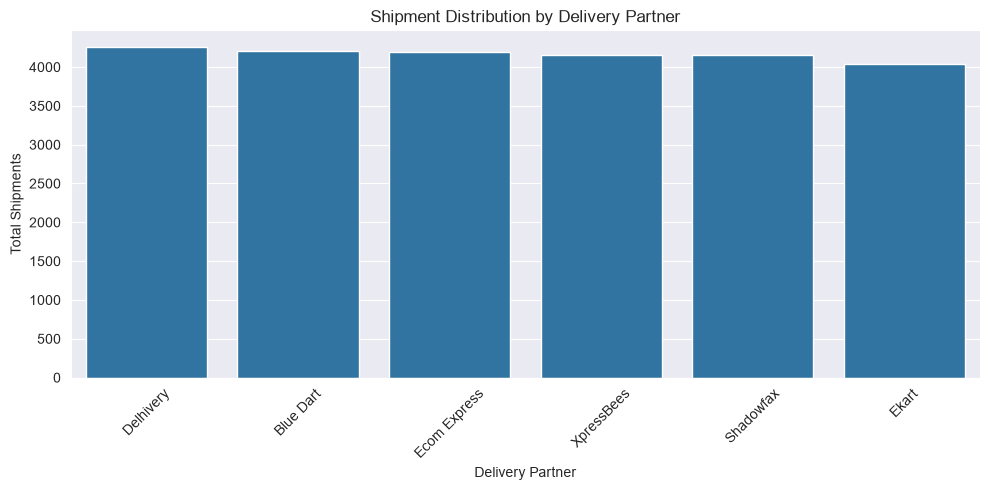

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=partner_orders,
    x='Delivery_Partner',
    y='Total_Shipments'
)

plt.title('Shipment Distribution by Delivery Partner')
plt.xlabel('Delivery Partner')
plt.ylabel('Total Shipments')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## SLA Breach Rate by Delivery Partner

In [47]:
partner_sla = (
    df.groupby('Delivery_Partner')
    .agg(
        Total_Shipments=('Order_ID', 'count'),
        SLA_Breaches=('Is_Delayed_SLA', 'sum'),
        SLA_Breach_Rate=('Is_Delayed_SLA', 'mean')
    )
    .reset_index()
)

partner_sla['SLA_Breach_Rate'] = (
    partner_sla['SLA_Breach_Rate'] * 100
).round(2)

partner_sla = partner_sla.sort_values(
    'SLA_Breach_Rate', ascending=False
)

partner_sla

,Delivery_Partner,Total_Shipments,SLA_Breaches,SLA_Breach_Rate
2,Ecom Express,4188,1640,39.16
5,XpressBees,4154,1450,34.91
1,Delhivery,4258,1185,27.83
3,Ekart,4036,860,21.31
0,Blue Dart,4210,668,15.87
4,Shadowfax,4154,577,13.89


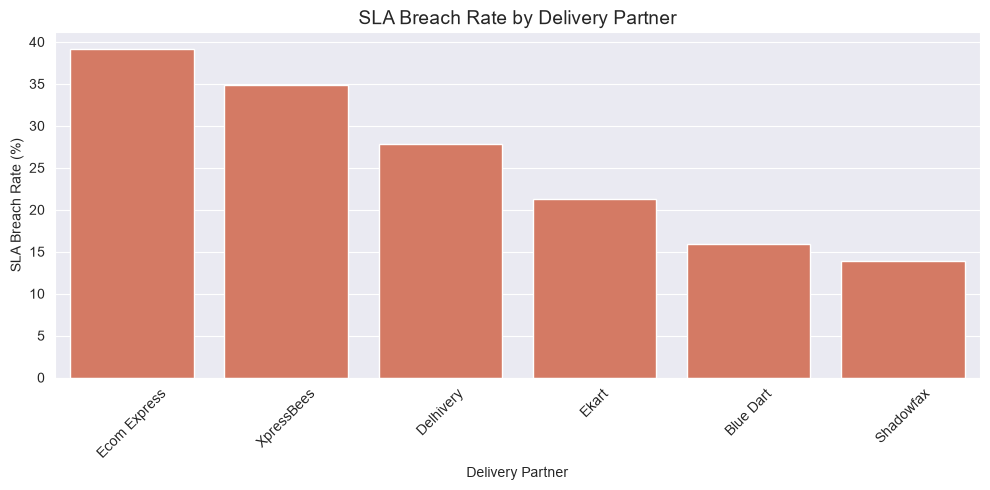

In [48]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=partner_sla,
    x='Delivery_Partner',
    y='SLA_Breach_Rate',
    color='#E76F51'
)

plt.title('SLA Breach Rate by Delivery Partner', fontsize=14)
plt.xlabel('Delivery Partner')
plt.ylabel('SLA Breach Rate (%)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Average Delivery Time by Delivery Partner

In [49]:
partner_delivery = (
    df.groupby('Delivery_Partner')
    .agg(
        Total_Shipments=('Order_ID', 'count'),
        Avg_Delivery_Days=('Actual_Delivery_Days', 'mean')
    )
    .reset_index()
)

partner_delivery['Avg_Delivery_Days'] = (
    partner_delivery['Avg_Delivery_Days'].round(2)
)

partner_delivery.sort_values(
    'Avg_Delivery_Days'
)

,Delivery_Partner,Total_Shipments,Avg_Delivery_Days
0,Blue Dart,4210,2.24
4,Shadowfax,4154,2.44
3,Ekart,4036,2.64
1,Delhivery,4258,2.74
5,XpressBees,4154,3.07
2,Ecom Express,4188,3.18


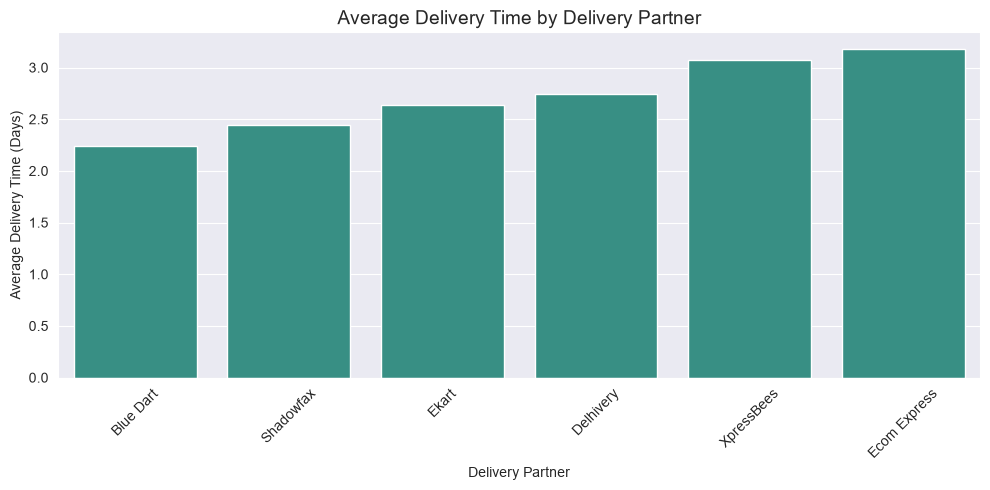

In [50]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=partner_delivery.sort_values('Avg_Delivery_Days'),
    x='Delivery_Partner',
    y='Avg_Delivery_Days',
    color='#2A9D8F'
)

plt.title('Average Delivery Time by Delivery Partner', fontsize=14)
plt.xlabel('Delivery Partner')
plt.ylabel('Average Delivery Time (Days)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## SLA Breach Rate by Logistics Zone

In [51]:
zone_sla = (
    df.groupby('Logistics_Zone')
    .agg(
        Total_Shipments=('Order_ID', 'count'),
        SLA_Breaches=('Is_Delayed_SLA', 'sum'),
        SLA_Breach_Rate=('Is_Delayed_SLA', 'mean'),
        Avg_Delivery_Days=('Actual_Delivery_Days', 'mean')
    )
    .reset_index()
)

zone_sla['SLA_Breach_Rate'] = (
    zone_sla['SLA_Breach_Rate'] * 100
).round(2)

zone_sla['Avg_Delivery_Days'] = (
    zone_sla['Avg_Delivery_Days'].round(2)
)

zone_sla.sort_values('SLA_Breach_Rate', ascending=False)

,Logistics_Zone,Total_Shipments,SLA_Breaches,SLA_Breach_Rate,Avg_Delivery_Days
0,Zone A (Intra-City),5001,3202,64.03,1.78
2,Zone C (Metro-to-Metro),6171,1636,26.51,2.87
1,Zone B (Within State/Region),6305,1397,22.16,2.07
3,Zone D (Rest of India),5485,130,2.37,3.42
4,Zone E (NE / J&K / Special),2038,15,0.74,4.70


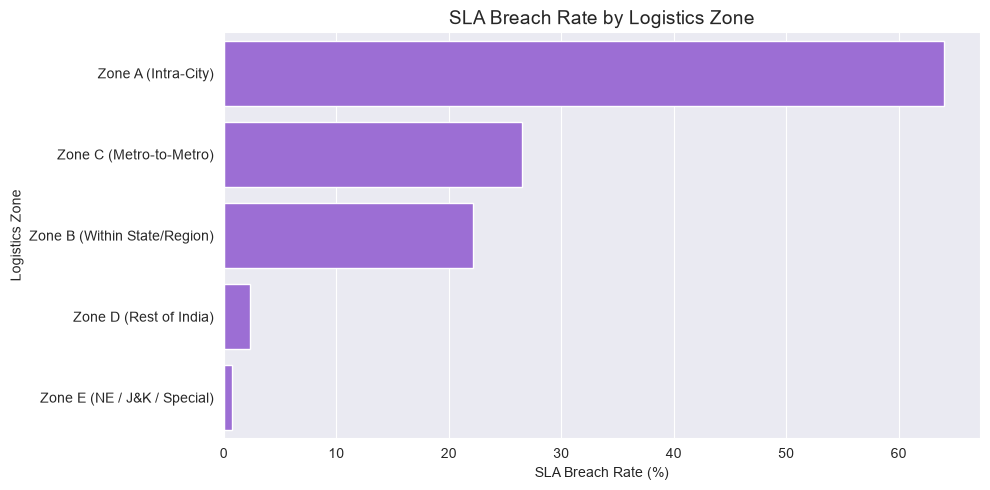

In [52]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=zone_sla.sort_values('SLA_Breach_Rate', ascending=False),
    x='SLA_Breach_Rate',
    y='Logistics_Zone',
    color='#9B5DE5'
)

plt.title('SLA Breach Rate by Logistics Zone', fontsize=14)
plt.xlabel('SLA Breach Rate (%)')
plt.ylabel('Logistics Zone')

plt.tight_layout()
plt.show()

## SLA Breach Rate by Shipment Mode

In [53]:
mode_sla = (
    df.groupby('Shipment_Mode')
    .agg(
        Total_Shipments=('Order_ID', 'count'),
        SLA_Breaches=('Is_Delayed_SLA', 'sum'),
        SLA_Breach_Rate=('Is_Delayed_SLA', 'mean'),
        Avg_Delivery_Days=('Actual_Delivery_Days', 'mean'),
        Avg_Shipping_Cost=('Shipping_Cost_INR', 'mean')
    )
    .reset_index()
)

mode_sla['SLA_Breach_Rate'] = (
    mode_sla['SLA_Breach_Rate'] * 100
).round(2)

mode_sla['Avg_Delivery_Days'] = mode_sla['Avg_Delivery_Days'].round(2)
mode_sla['Avg_Shipping_Cost'] = mode_sla['Avg_Shipping_Cost'].round(2)

mode_sla.sort_values('SLA_Breach_Rate', ascending=False)

,Shipment_Mode,Total_Shipments,SLA_Breaches,SLA_Breach_Rate,Avg_Delivery_Days,Avg_Shipping_Cost
1,Surface,20841,5489,26.34,2.72,126.02
0,Air,4159,891,21.42,2.70,227.89


## SLA Breach Rate by Weather Condition

In [54]:
weather_sla = (
    df.groupby('Weather_Condition')
    .agg(
        Total_Shipments=('Order_ID', 'count'),
        SLA_Breaches=('Is_Delayed_SLA', 'sum'),
        SLA_Breach_Rate=('Is_Delayed_SLA', 'mean'),
        Avg_Delivery_Days=('Actual_Delivery_Days', 'mean')
    )
    .reset_index()
)

weather_sla['SLA_Breach_Rate'] = (
    weather_sla['SLA_Breach_Rate'] * 100
).round(2)

weather_sla['Avg_Delivery_Days'] = (
    weather_sla['Avg_Delivery_Days'].round(2)
)

weather_sla.sort_values(
    'SLA_Breach_Rate',
    ascending=False
)

,Weather_Condition,Total_Shipments,SLA_Breaches,SLA_Breach_Rate,Avg_Delivery_Days
2,Monsoon Storm,1272,739,58.10,3.53
1,Fog/Smog,2514,889,35.36,3.00
3,Rainy,5091,1472,28.91,2.82
0,Clear,16123,3280,20.34,2.58


## SLA Breach Rate by Festival Peak

In [55]:
festival_sla = (
    df.groupby('Festival_Peak')
    .agg(
        Total_Shipments=('Order_ID', 'count'),
        SLA_Breaches=('Is_Delayed_SLA', 'sum'),
        SLA_Breach_Rate=('Is_Delayed_SLA', 'mean'),
        Avg_Delivery_Days=('Actual_Delivery_Days', 'mean'),
        Avg_Shipping_Cost=('Shipping_Cost_INR', 'mean')
    )
    .reset_index()
)

festival_sla['SLA_Breach_Rate'] = (
    festival_sla['SLA_Breach_Rate'] * 100
).round(2)

festival_sla['Avg_Delivery_Days'] = (
    festival_sla['Avg_Delivery_Days'].round(2)
)

festival_sla['Avg_Shipping_Cost'] = (
    festival_sla['Avg_Shipping_Cost'].round(2)
)

festival_sla

,Festival_Peak,Total_Shipments,SLA_Breaches,SLA_Breach_Rate,Avg_Delivery_Days,Avg_Shipping_Cost
0,0,21305,4522,21.23,2.61,142.82
1,1,3695,1858,50.28,3.35,143.83


## SLA Breach Rate by Distance Category

In [56]:
df['Distance_Category'] = pd.cut(
    df['Distance_km'],
    bins=[0, 100, 300, 700, 1500, float('inf')],
    labels=['Very Short', 'Short', 'Medium', 'Long', 'Very Long']
)

distance_sla = (
    df.groupby('Distance_Category', observed=False)
    .agg(
        Total_Shipments=('Order_ID', 'count'),
        SLA_Breaches=('Is_Delayed_SLA', 'sum'),
        SLA_Breach_Rate=('Is_Delayed_SLA', 'mean'),
        Avg_Delivery_Days=('Actual_Delivery_Days', 'mean'),
        Avg_Shipping_Cost=('Shipping_Cost_INR', 'mean')
    )
    .reset_index()
)

distance_sla['SLA_Breach_Rate'] = (
    distance_sla['SLA_Breach_Rate'] * 100
).round(2)

distance_sla['Avg_Delivery_Days'] = (
    distance_sla['Avg_Delivery_Days'].round(2)
)

distance_sla['Avg_Shipping_Cost'] = (
    distance_sla['Avg_Shipping_Cost'].round(2)
)

distance_sla

,Distance_Category,Total_Shipments,SLA_Breaches,SLA_Breach_Rate,Avg_Delivery_Days,Avg_Shipping_Cost
0,Very Short,5777,3313,57.35,1.79,99.92
1,Short,3151,661,20.98,2.04,115.10
2,Medium,4266,759,17.79,2.35,131.68
3,Long,6968,917,13.16,3.11,161.00
4,Very Long,4838,730,15.09,4.02,196.51


## Average Promised SLA Days by Distance Category

In [57]:
distance_edd = (
    df.groupby('Distance_Category', observed=False)
    .agg(
        Avg_Promised_SLA_Days=('SLA_Promised_Days', 'mean'),
        Avg_Actual_Delivery_Days=('Actual_Delivery_Days', 'mean'),
        Total_Shipments=('Order_ID', 'count')
    )
    .reset_index()
)

distance_edd['Avg_Promised_SLA_Days'] = (
    distance_edd['Avg_Promised_SLA_Days'].round(2)
)

distance_edd['Avg_Actual_Delivery_Days'] = (
    distance_edd['Avg_Actual_Delivery_Days'].round(2)
)

distance_edd

,Distance_Category,Avg_Promised_SLA_Days,Avg_Actual_Delivery_Days,Total_Shipments
0,Very Short,1.13,1.79,5777
1,Short,2.00,2.04,3151
2,Medium,2.76,2.35,4266
3,Long,3.90,3.11,6968
4,Very Long,4.73,4.02,4838


# Exploratory Data Analysis (EDA)

## 1. Overall Dataset Performance

| Metric                    |    Result |
| ------------------------- | --------: |
| Total Shipments           |    25,000 |
| Logistics Partners        |         6 |
| Average Delivery Time     | 2.72 days |
| Average Shipping Cost     |   ₹142.97 |
| Average Shipment Distance | 781.68 km |
| Overall SLA Breach Rate   |    25.52% |

**Observation:**

Approximately 25.52% of shipments breached their promised delivery SLA. This provides the baseline against which different operational dimensions were evaluated.

---

## 2. Shipment Distribution by Delivery Partner

| Delivery Partner | Total Shipments |
| ---------------- | --------------: |
| Delhivery        |           4,258 |
| Blue Dart        |           4,210 |
| Ecom Express     |           4,188 |
| XpressBees       |           4,154 |
| Shadowfax        |           4,154 |
| Ekart            |           4,036 |

**Observation:**

Shipment distribution is relatively balanced across all six logistics partners. No single partner dominates the shipment volume.

This provides a useful starting point for comparing delivery performance across partners.

---

## 3. SLA Breach Rate by Delivery Partner

| Delivery Partner | SLA Breach Rate |
| ---------------- | --------------: |
| Ecom Express     |          39.16% |
| XpressBees       |          34.91% |
| Delhivery        |          27.83% |
| Ekart            |          21.31% |
| Blue Dart        |          15.87% |
| Shadowfax        |          13.89% |

**Key Insights:**

* Ecom Express recorded the highest SLA breach rate at 39.16%.
* Shadowfax recorded the lowest rate at 13.89%.
* Ecom Express had approximately 2.82 times the breach rate of Shadowfax.

This highlights differences in SLA performance across logistics partners within the synthetic dataset.

---

## 4. Average Delivery Time by Delivery Partner

| Delivery Partner | Average Delivery Time |
| ---------------- | --------------------: |
| Blue Dart        |             2.24 days |
| Shadowfax        |             2.44 days |
| Ekart            |             2.64 days |
| Delhivery        |             2.74 days |
| XpressBees       |             3.07 days |
| Ecom Express     |             3.18 days |

**Key Insights:**

* Blue Dart recorded the lowest average delivery time of 2.24 days.
* Ecom Express recorded the highest average delivery time of 3.18 days.
* The difference between the two partners was 0.94 days.

The average delivery-time comparison is broadly consistent with the SLA breach analysis. However, differences in shipment distance, delivery zones and shipment modes may also influence these results.

---

## 5. SLA Breach Rate by Logistics Zone

| Logistics Zone               | SLA Breach Rate | Average Delivery Time |
| ---------------------------- | --------------: | --------------------: |
| Zone A – Intra-City          |          64.03% |             1.78 days |
| Zone C – Metro-to-Metro      |          26.51% |             2.87 days |
| Zone B – Within State/Region |          22.16% |             2.07 days |
| Zone D – Rest of India       |           2.37% |             3.42 days |
| Zone E – NE / J&K / Special  |           0.74% |             4.70 days |

**Key Insights:**

* Zone A recorded the highest SLA breach rate at 64.03%.
* Zone E recorded the lowest breach rate at 0.74%.
* Zone E had the longest average delivery time at 4.70 days.

This demonstrates that longer delivery duration does not necessarily indicate poor SLA performance. The promised delivery window is also important.

---

## 6. SLA Breach Rate by Shipment Mode

| Shipment Mode | SLA Breach Rate | Average Delivery Time | Average Shipping Cost |
| ------------- | --------------: | --------------------: | --------------------: |
| Surface       |          26.34% |             2.72 days |               ₹126.02 |
| Air           |          21.42% |             2.70 days |               ₹227.89 |

**Key Insights:**

* Surface shipments recorded a higher SLA breach rate than Air shipments.
* Air shipments had a 4.92 percentage-point lower breach rate.
* Air shipping cost approximately 81% more than Surface shipping.
* Average delivery times were almost identical.

This highlights a cost-versus-SLA-performance trade-off between the two shipment modes.

---

## 7. SLA Breach Rate by Weather Condition

| Weather Condition | SLA Breach Rate | Average Delivery Time |
| ----------------- | --------------: | --------------------: |
| Monsoon Storm     |          58.10% |             3.53 days |
| Fog/Smog          |          35.36% |             3.00 days |
| Rainy             |          28.91% |             2.82 days |
| Clear             |          20.34% |             2.58 days |

**Key Insights:**

* Monsoon Storm recorded the highest SLA breach rate at 58.10%.
* Clear weather recorded the lowest rate at 20.34%.
* Average delivery time was also highest during Monsoon Storm conditions.

Weather conditions appear to be associated with delivery performance.

Potential business applications include weather-based delivery risk scoring and adjusting EDD predictions during adverse weather conditions.

---

## 8. SLA Breach Rate by Festival Peak

| Metric                | Non-Festival | Festival Peak |
| --------------------- | -----------: | ------------: |
| Total Shipments       |       21,305 |         3,695 |
| SLA Breaches          |        4,522 |         1,858 |
| SLA Breach Rate       |       21.23% |        50.28% |
| Average Delivery Time |    2.61 days |     3.35 days |
| Average Shipping Cost |      ₹142.82 |       ₹143.83 |

**Key Insights:**

* Festival-period shipments recorded a 50.28% SLA breach rate.
* Non-festival shipments recorded a 21.23% breach rate.
* Festival shipments had approximately 2.37 times the breach rate.
* Average delivery time increased by 0.74 days during festival peaks.
* Average shipping cost remained almost unchanged.

This suggests that festival periods are associated with increased delivery delays.

Potential business applications include capacity planning, additional delivery resources and festival-aware EDD prediction.

---

## 9. SLA Breach Rate by Distance Category

| Distance Category | SLA Breach Rate | Average Delivery Time | Average Shipping Cost |
| ----------------- | --------------: | --------------------: | --------------------: |
| Very Short        |          57.35% |             1.79 days |                ₹99.92 |
| Short             |          20.98% |             2.04 days |               ₹115.10 |
| Medium            |          17.79% |             2.35 days |               ₹131.68 |
| Long              |          13.16% |             3.11 days |               ₹161.00 |
| Very Long         |          15.09% |             4.02 days |               ₹196.51 |

**Key Insights:**

* Very Short shipments recorded the highest SLA breach rate at 57.35%.
* Long-distance shipments recorded the lowest rate at 13.16%.
* Very Long shipments showed a slight increase in breach rate compared with Long shipments.
* Shipping costs generally increased with shipment distance.

An unexpected observation was that shorter-distance shipments experienced higher SLA breach rates despite having lower average delivery times.

This indicated a need to investigate promised SLA durations.

---

## 10. Average Promised SLA vs Actual Delivery Time by Distance

| Distance Category | Average Promised SLA | Average Actual Delivery |
| ----------------- | -------------------: | ----------------------: |
| Very Short        |            1.13 days |               1.79 days |
| Short             |            2.00 days |               2.04 days |
| Medium            |            2.76 days |               2.35 days |
| Long              |            3.90 days |               3.11 days |
| Very Long         |            4.73 days |               4.02 days |

**Key Insights:**

* Very Short shipments had an average promised SLA of only 1.13 days, compared with 1.79 days of actual delivery time.
* Short shipments had almost identical promised and actual delivery durations.
* Medium, Long and Very Long shipments had average actual delivery durations below their average promised SLA.

This explains why shorter-distance shipments can have higher SLA breach rates despite being delivered faster in absolute terms.

**Business Recommendation:**

SLA commitments should be realistic and based on shipment distance and operational conditions. Aggressive delivery promises can increase the risk of SLA breaches.

---

# Overall EDA Findings

The exploratory analysis identified several important patterns in the synthetic logistics dataset:

1. **Delivery Partner Performance:** SLA breach rates vary considerably across logistics partners.
2. **Logistics Zone:** Intra-city shipments show unexpectedly high SLA breach rates.
3. **Shipment Mode:** Air shipments have lower SLA breach rates but substantially higher shipping costs.
4. **Weather Conditions:** Adverse weather conditions are associated with higher SLA breach rates and longer delivery times.
5. **Festival Peaks:** Festival-period shipments show considerably higher delivery delays.
6. **Shipment Distance:** Longer shipments generally have higher shipping costs and longer delivery times.
7. **Promised SLA:** Short-distance shipments have particularly tight delivery commitments, helping explain their higher breach rates.

## Model 1: Delivery Time Prediction

### Understanding the target variable

In [58]:
# Target variable analysis

print("TARGET VARIABLE: Transit_Time_Hours")

print("\nDescriptive Statistics:")
display(df['Transit_Time_Hours'].describe())

print("\nMissing Values:")
print(df['Transit_Time_Hours'].isnull().sum())

print("\nUnique Values:")
print(df['Transit_Time_Hours'].nunique())

TARGET VARIABLE: Transit_Time_Hours

Descriptive Statistics:


count    25000.000000
mean        43.943500
std         26.551341
min          4.000000
25%         23.500000
50%         39.000000
75%         59.100000
max        191.300000
Name: Transit_Time_Hours, dtype: float64


Missing Values:
0

Unique Values:
1342


## Visualising Target Variable Distribution

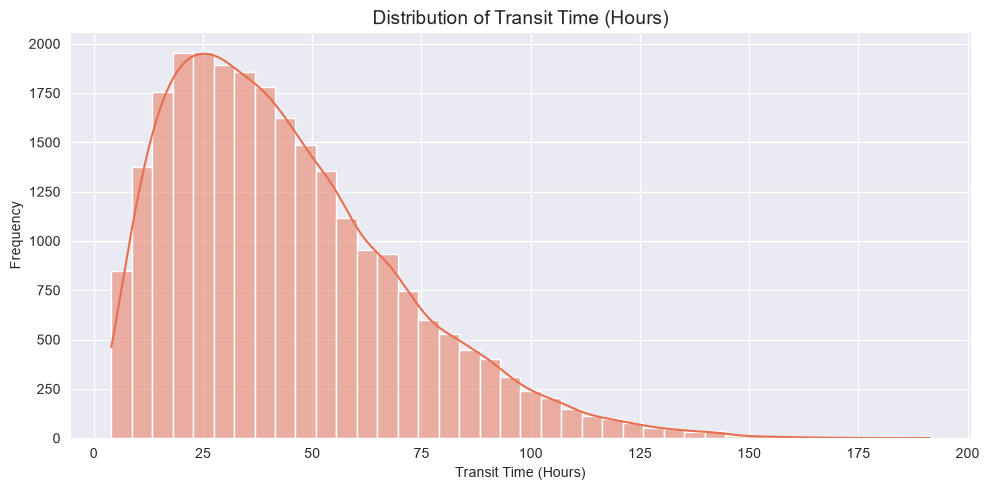

In [59]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['Transit_Time_Hours'],
    bins=40,
    kde=True,
    color='#E76F51'
)

plt.title('Distribution of Transit Time (Hours)', fontsize=14)
plt.xlabel('Transit Time (Hours)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

## Checking target variable skewness

In [60]:
target_skewness = df['Transit_Time_Hours'].skew()
target_kurtosis = df['Transit_Time_Hours'].kurt()

print("Target Skewness:", round(target_skewness, 3))
print("Target Kurtosis:", round(target_kurtosis, 3))

if target_skewness > 0:
    print("Distribution: Positively Skewed (Right-Skewed)")
elif target_skewness < 0:
    print("Distribution: Negatively Skewed (Left-Skewed)")
else:
    print("Distribution: Approximately Symmetrical")

Target Skewness: 0.948
Target Kurtosis: 0.804
Distribution: Positively Skewed (Right-Skewed)


## Feature Availability & Data Leakage Check

In [61]:
print("DATASET COLUMNS:")
print(df.columns.tolist())

print("\nDATA TYPES:")
display(df.dtypes)

print("\nSAMPLE RECORDS:")
display(df.head())

DATASET COLUMNS:
['Order_ID', 'Delivery_Partner', 'Origin_City', 'Origin_Pincode', 'Destination_City', 'Destination_Pincode', 'Logistics_Zone', 'Distance_km', 'Shipment_Mode', 'Weight_kg', 'Is_COD', 'Shipping_Cost_INR', 'Weather_Condition', 'Festival_Peak', 'Order_Timestamp', 'Dispatch_Timestamp', 'Pickup_Delay_Hours', 'Transit_Time_Hours', 'SLA_Promised_Days', 'Expected_Delivery_Timestamp', 'Expected_Delivery_Date', 'Actual_Delivery_Days', 'Is_Delayed_SLA', 'Distance_Category']

DATA TYPES:


Order_ID                               object
Delivery_Partner                       object
Origin_City                            object
Origin_Pincode                          int64
Destination_City                       object
Destination_Pincode                     int64
Logistics_Zone                         object
Distance_km                           float64
Shipment_Mode                          object
Weight_kg                             float64
Is_COD                                  int64
Shipping_Cost_INR                     float64
Weather_Condition                      object
Festival_Peak                           int64
Order_Timestamp                datetime64[ns]
Dispatch_Timestamp             datetime64[ns]
Pickup_Delay_Hours                    float64
Transit_Time_Hours                    float64
SLA_Promised_Days                       int64
Expected_Delivery_Timestamp    datetime64[ns]
Expected_Delivery_Date         datetime64[ns]
Actual_Delivery_Days              


SAMPLE RECORDS:


,Order_ID,Delivery_Partner,Origin_City,Origin_Pincode,Destination_City,Destination_Pincode,Logistics_Zone,Distance_km,Shipment_Mode,Weight_kg,...,Order_Timestamp,Dispatch_Timestamp,Pickup_Delay_Hours,Transit_Time_Hours,SLA_Promised_Days,Expected_Delivery_Timestamp,Expected_Delivery_Date,Actual_Delivery_Days,Is_Delayed_SLA,Distance_Category
0,IND2026000000,XpressBees,Kolkata,700012,Kolkata,705044,Zone B (Within State/Region),53.5,Surface,0.13,...,2026-03-05 03:00:00,2026-03-05 08:18:00,5.3,55.4,2,2026-03-07 15:42:00,2026-03-07,3,1,Very Short
1,IND2026000001,Ecom Express,Chennai,600022,Kolkata,700087,Zone C (Metro-to-Metro),1497.5,Surface,2.40,...,2026-03-10 08:00:00,2026-03-10 11:24:00,3.4,85.3,3,2026-03-14 00:42:00,2026-03-14,4,1,Long
2,IND2026000002,Ekart,Mumbai,400055,Jaipur,316042,Zone D (Rest of India),941.3,Surface,0.31,...,2026-09-23 04:00:00,2026-09-23 10:54:00,6.9,52.4,5,2026-09-25 15:18:00,2026-09-25,3,0,Long
3,IND2026000003,Ecom Express,Chennai,600088,Chennai,605080,Zone B (Within State/Region),193.4,Surface,0.86,...,2026-06-01 12:00:00,2026-06-01 18:42:00,6.7,16.9,2,2026-06-02 11:36:00,2026-06-02,1,0,Short
4,IND2026000004,Ecom Express,Kolkata,700076,Kolkata,707050,Zone B (Within State/Region),349.8,Surface,0.42,...,2026-01-19 05:00:00,2026-01-19 11:00:00,6.0,37.2,2,2026-01-21 00:12:00,2026-01-21,2,0,Medium


## Creating a separate ML dataset

In [62]:
# Creating a copy for Machine Learning

ml_df = df.copy()

# Extracting date and time features

ml_df['Order_Hour'] = ml_df['Order_Timestamp'].dt.hour
ml_df['Order_DayOfWeek'] = ml_df['Order_Timestamp'].dt.dayofweek
ml_df['Order_Month'] = ml_df['Order_Timestamp'].dt.month

ml_df['Dispatch_Hour'] = ml_df['Dispatch_Timestamp'].dt.hour
ml_df['Dispatch_DayOfWeek'] = ml_df['Dispatch_Timestamp'].dt.dayofweek
ml_df['Dispatch_Month'] = ml_df['Dispatch_Timestamp'].dt.month

# Selecting features

features = [
    'Delivery_Partner',
    'Logistics_Zone',
    'Distance_km',
    'Shipment_Mode',
    'Weight_kg',
    'Weather_Condition',
    'Festival_Peak',
    'Is_COD',
    'Shipping_Cost_INR',
    'Pickup_Delay_Hours',
    'Order_Hour',
    'Order_DayOfWeek',
    'Order_Month',
    'Dispatch_Hour',
    'Dispatch_DayOfWeek',
    'Dispatch_Month'
]

# Defining target

target = 'Transit_Time_Hours'

# Creating final modelling dataset

ml_df = ml_df[features + [target]]

print("ML Dataset Shape:", ml_df.shape)

print("\nMissing Values:")
print(ml_df.isnull().sum().sum())

display(ml_df.head())

ML Dataset Shape: (25000, 17)

Missing Values:
0


,Delivery_Partner,Logistics_Zone,Distance_km,Shipment_Mode,Weight_kg,Weather_Condition,Festival_Peak,Is_COD,Shipping_Cost_INR,Pickup_Delay_Hours,Order_Hour,Order_DayOfWeek,Order_Month,Dispatch_Hour,Dispatch_DayOfWeek,Dispatch_Month,Transit_Time_Hours
0,XpressBees,Zone B (Within State/Region),53.5,Surface,0.13,Clear,1,0,42.48,5.3,3,3,3,8,3,3,55.4
1,Ecom Express,Zone C (Metro-to-Metro),1497.5,Surface,2.40,Fog/Smog,0,0,143.10,3.4,8,1,3,11,1,3,85.3
2,Ekart,Zone D (Rest of India),941.3,Surface,0.31,Clear,0,1,120.23,6.9,4,2,9,10,2,9,52.4
3,Ecom Express,Zone B (Within State/Region),193.4,Surface,0.86,Clear,0,1,98.22,6.7,12,0,6,18,0,6,16.9
4,Ecom Express,Zone B (Within State/Region),349.8,Surface,0.42,Fog/Smog,0,0,61.55,6.0,5,0,1,11,0,1,37.2


In [ ]:
## Checking feature data types and missing values

In [63]:
print("DATA TYPES:")
display(ml_df.dtypes)

print("\nMISSING VALUES BY COLUMN:")
display(ml_df.isnull().sum())

print("\nCATEGORICAL FEATURES:")
print(ml_df.select_dtypes(include=['object']).columns.tolist())

DATA TYPES:


Delivery_Partner       object
Logistics_Zone         object
Distance_km           float64
Shipment_Mode          object
Weight_kg             float64
Weather_Condition      object
Festival_Peak           int64
Is_COD                  int64
Shipping_Cost_INR     float64
Pickup_Delay_Hours    float64
Order_Hour              int32
Order_DayOfWeek         int32
Order_Month             int32
Dispatch_Hour           int32
Dispatch_DayOfWeek      int32
Dispatch_Month          int32
Transit_Time_Hours    float64
dtype: object


MISSING VALUES BY COLUMN:


Delivery_Partner      0
Logistics_Zone        0
Distance_km           0
Shipment_Mode         0
Weight_kg             0
Weather_Condition     0
Festival_Peak         0
Is_COD                0
Shipping_Cost_INR     0
Pickup_Delay_Hours    0
Order_Hour            0
Order_DayOfWeek       0
Order_Month           0
Dispatch_Hour         0
Dispatch_DayOfWeek    0
Dispatch_Month        0
Transit_Time_Hours    0
dtype: int64


CATEGORICAL FEATURES:
['Delivery_Partner', 'Logistics_Zone', 'Shipment_Mode', 'Weather_Condition']


## Separate Features (X) and Target (y)

In [64]:
# Independent variables
X = ml_df.drop(columns=['Transit_Time_Hours'])

# Dependent variable
y = ml_df['Transit_Time_Hours']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nCategorical Features:")
print(X.select_dtypes(include=['object']).columns.tolist())

print("\nNumerical Features:")
print(X.select_dtypes(exclude=['object']).columns.tolist())

Features Shape: (25000, 16)
Target Shape: (25000,)

Categorical Features:
['Delivery_Partner', 'Logistics_Zone', 'Shipment_Mode', 'Weather_Condition']

Numerical Features:
['Distance_km', 'Weight_kg', 'Festival_Peak', 'Is_COD', 'Shipping_Cost_INR', 'Pickup_Delay_Hours', 'Order_Hour', 'Order_DayOfWeek', 'Order_Month', 'Dispatch_Hour', 'Dispatch_DayOfWeek', 'Dispatch_Month']


## Chronological Train-Test Split

In [65]:
# Chronological sorting using original dispatch timestamp

sorted_index = (
    df.loc[ml_df.index]
    .sort_values('Dispatch_Timestamp')
    .index
)

# Reorder features and target

X = X.loc[sorted_index]
y = y.loc[sorted_index]

# 80-20 chronological split

split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Period:")
print(df.loc[X_train.index, 'Dispatch_Timestamp'].min())
print(df.loc[X_train.index, 'Dispatch_Timestamp'].max())

print("\nTesting Period:")
print(df.loc[X_test.index, 'Dispatch_Timestamp'].min())
print(df.loc[X_test.index, 'Dispatch_Timestamp'].max())

Training Features: (20000, 16)
Testing Features: (5000, 16)
Training Target: (20000,)
Testing Target: (5000,)

Training Period:
2026-01-01 02:12:00
2026-08-05 23:00:00

Testing Period:
2026-08-06 03:12:00
2026-09-28 20:48:00


## Building the Preprocessing Pipeline

In [66]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identifying categorical and numerical columns

categorical_features = X.select_dtypes(include=['object']).columns.tolist()

numerical_features = X.select_dtypes(exclude=['object']).columns.tolist()

# Creating preprocessing pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', StandardScaler(), numerical_features)
    ]
)

print("Categorical Features:", len(categorical_features))
print("Numerical Features:", len(numerical_features))

print("\nPreprocessing Pipeline Created Successfully!")

Categorical Features: 4
Numerical Features: 12

Preprocessing Pipeline Created Successfully!


## Linear Regression

In [67]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

# Creating Linear Regression pipeline

lr_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LinearRegression())
    ]
)

# Train the model

lr_model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [68]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict on test data
y_pred_lr = lr_model.predict(X_test)

# Calculate evaluation metrics
mae_lr = mean_absolute_error(y_test, y_pred_lr)

rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

r2_lr = r2_score(y_test, y_pred_lr)

# Display results
print("LINEAR REGRESSION PERFORMANCE")
print("--------------------------------")
print("MAE:", round(mae_lr, 2), "hours")
print("RMSE:", round(rmse_lr, 2), "hours")
print("R2 Score:", round(r2_lr, 4))

LINEAR REGRESSION PERFORMANCE
--------------------------------
MAE: 7.29 hours
RMSE: 9.92 hours
R2 Score: 0.8624


## Actual vs Predicted Transit Time

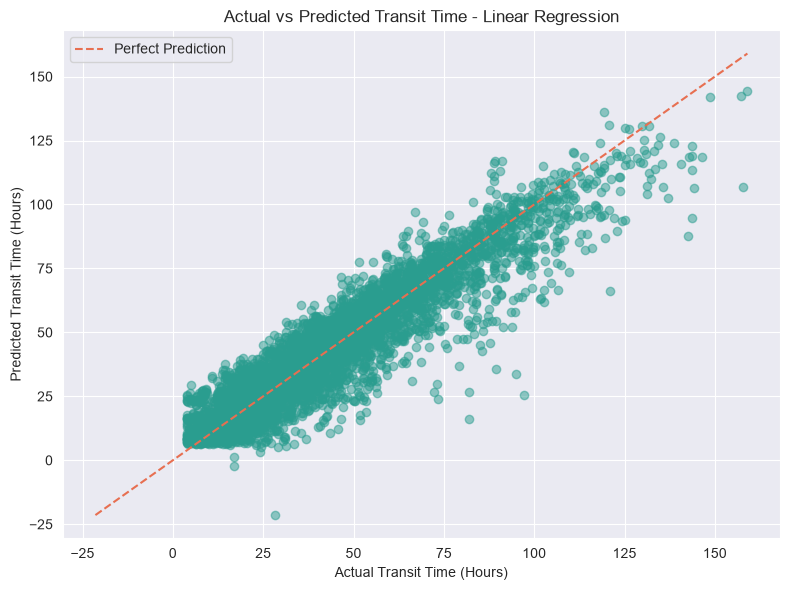

In [69]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_lr,
    alpha=0.5,
    color='#2A9D8F'
)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred_lr.min())
max_value = max(y_test.max(), y_pred_lr.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--',
    color='#E76F51',
    label='Perfect Prediction'
)

plt.title('Actual vs Predicted Transit Time - Linear Regression')
plt.xlabel('Actual Transit Time (Hours)')
plt.ylabel('Predicted Transit Time (Hours)')
plt.legend()
plt.tight_layout()
plt.show()

## Random Forest Regressor

In [71]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

rf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [72]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Make predictions
y_pred_rf = rf_model.predict(X_test)

# Calculate evaluation metrics
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Model Performance")
print("--------------------------------")
print(f"MAE  : {mae_rf:.2f} hours")
print(f"RMSE : {rmse_rf:.2f} hours")
print(f"R²   : {r2_rf:.4f}")

Random Forest Model Performance
--------------------------------
MAE  : 7.19 hours
RMSE : 9.66 hours
R²   : 0.8694


## XGBoost Regressor

In [74]:
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline

xgb_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', XGBRegressor(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            objective='reg:squarederror',
            random_state=42,
            n_jobs=-1
        ))
    ]
)

xgb_model.fit(X_train, y_train)

print("XGBoost Model Trained Successfully!")

XGBoost Model Trained Successfully!


In [75]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Make predictions
y_pred_xgb = xgb_model.predict(X_test)

# Calculate evaluation metrics
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)

print("XGBoost Model Performance")
print("--------------------------------")
print(f"MAE  : {mae_xgb:.2f} hours")
print(f"RMSE : {rmse_xgb:.2f} hours")
print(f"R²   : {r2_xgb:.4f}")

XGBoost Model Performance
--------------------------------
MAE  : 6.73 hours
RMSE : 9.22 hours
R²   : 0.8812


## Visualizing all three models

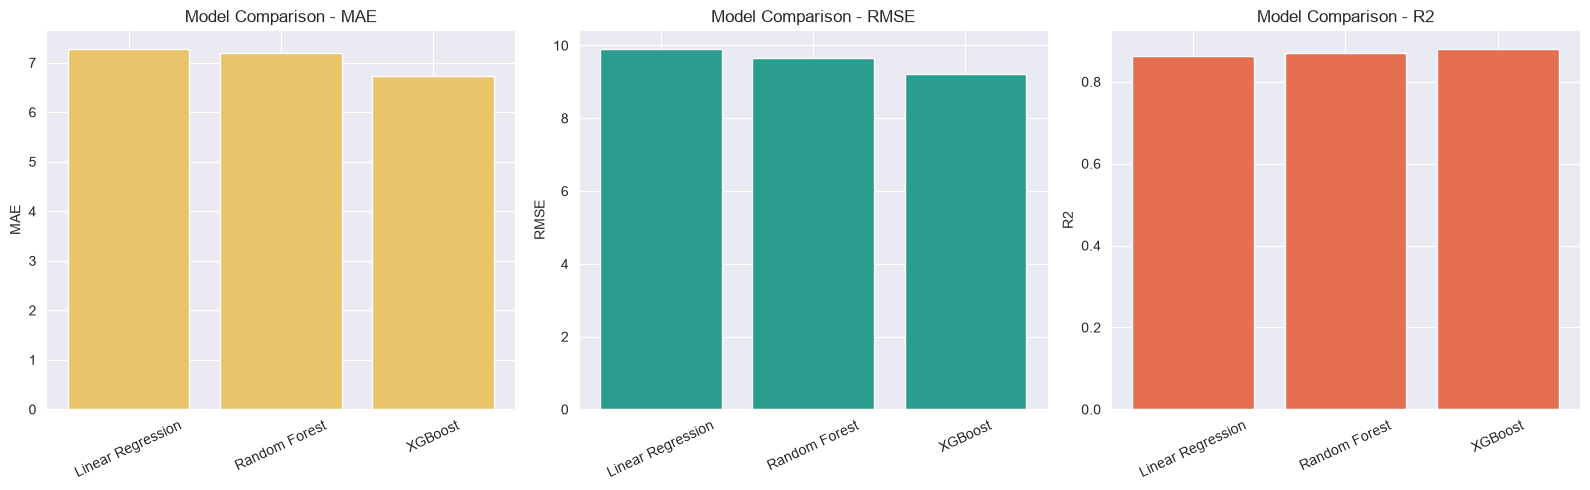

,Model,MAE,RMSE,R2
0,Linear Regression,7.286996,9.917175,0.862401
1,Random Forest,7.188131,9.660529,0.869431
2,XGBoost,6.734688,9.215993,0.881171


In [76]:
model_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest', 'XGBoost'],
    'MAE': [mae_lr, mae_rf, mae_xgb],
    'RMSE': [rmse_lr, rmse_rf, rmse_xgb],
    'R2': [r2_lr, r2_rf, r2_xgb]
})

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ['MAE', 'RMSE', 'R2']
colors = ['#E9C46A', '#2A9D8F', '#E76F51']

for ax, metric, color in zip(axes, metrics, colors):
    ax.bar(
        model_comparison['Model'],
        model_comparison[metric],
        color=color
    )
    ax.set_title(f'Model Comparison - {metric}')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

model_comparison

## Model Selection

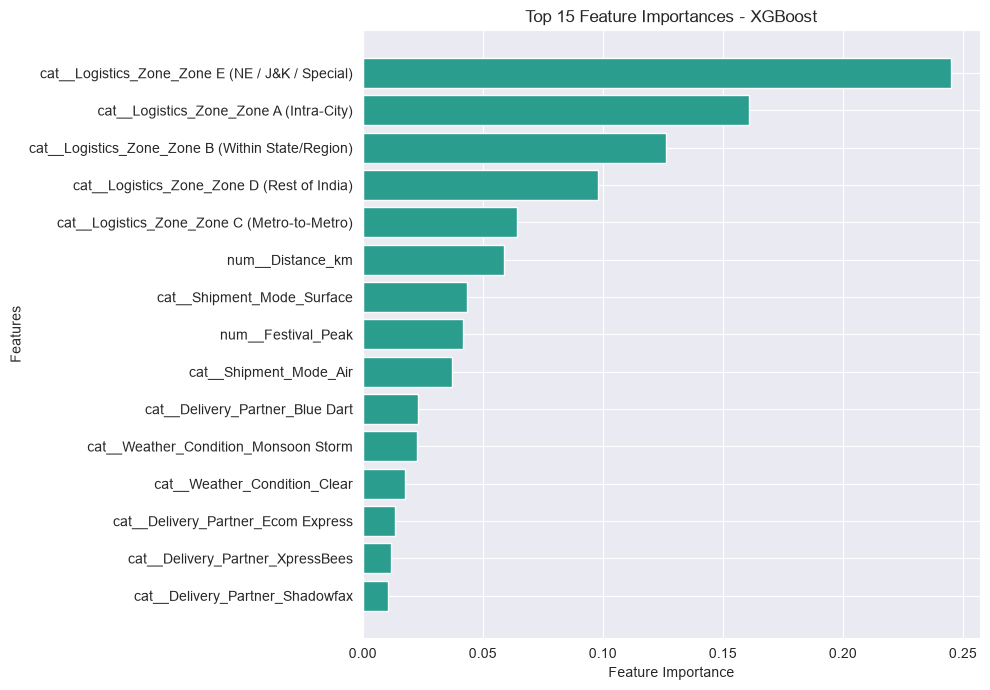

,Feature,Importance
10,cat__Logistics_Zone_Zone E (NE / J&K / Special),0.244866
6,cat__Logistics_Zone_Zone A (Intra-City),0.161093
7,cat__Logistics_Zone_Zone B (Within State/Region),0.126194
9,cat__Logistics_Zone_Zone D (Rest of India),0.098059
8,cat__Logistics_Zone_Zone C (Metro-to-Metro),0.064319
17,num__Distance_km,0.058935
12,cat__Shipment_Mode_Surface,0.043560
19,num__Festival_Peak,0.041729
11,cat__Shipment_Mode_Air,0.037141
0,cat__Delivery_Partner_Blue Dart,0.023165


In [77]:
# Extract feature importance from trained XGBoost model
xgb_estimator = xgb_model.named_steps['model']

# Get feature names after preprocessing
feature_names = (
    xgb_model.named_steps['preprocessor']
    .get_feature_names_out()
)

# Create feature importance dataframe
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': xgb_estimator.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15 features
top_features = feature_importance.head(15)

# Visualize
plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'][::-1],
    top_features['Importance'][::-1],
    color='#2A9D8F'
)

plt.title('Top 15 Feature Importances - XGBoost')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

top_features

In [78]:
# Extracting original feature names from encoded feature names
feature_importance['Original_Feature'] = (
    feature_importance['Feature']
    .str.replace(r'^(cat__|num__)', '', regex=True)
    .str.replace(r'_[^_]+$', '', regex=True)
)

# Grouping importance by original feature
grouped_importance = (
    feature_importance
    .groupby('Original_Feature')['Importance']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# Displaying grouped feature importance
grouped_importance

,Original_Feature,Importance
0,Logistics_Zone,0.694532
1,Shipment_Mode,0.080701
2,Delivery_Partner,0.066062
3,Distance,0.058935
4,Weather_Condition,0.046726
5,Festival,0.041729
6,Order,0.003154
7,Dispatch,0.003101
8,Shipping_Cost,0.001780
9,Weight,0.001164


In [79]:
import joblib

# Saving the complete pipeline, including preprocessing
joblib.dump(
    xgb_model,
    'xgboost_delivery_time_model.pkl'
)

print("XGBoost model saved successfully!")

XGBoost model saved successfully!


In [80]:
# Generating predicted transit time for test shipments
predicted_transit_hours = xgb_model.predict(X_test)

# Creating prediction results dataframe
prediction_results = pd.DataFrame({
    'Order_ID': df.loc[X_test.index, 'Order_ID'].values,
    'Dispatch_Timestamp': df.loc[X_test.index, 'Dispatch_Timestamp'].values,
    'Actual_Transit_Hours': y_test.values,
    'Predicted_Transit_Hours': predicted_transit_hours
})

# Calculating predicted delivery timestamp
prediction_results['Predicted_Delivery_Timestamp'] = (
    prediction_results['Dispatch_Timestamp']
    + pd.to_timedelta(
        prediction_results['Predicted_Transit_Hours'],
        unit='h'
    )
)

prediction_results.head(10)

,Order_ID,Dispatch_Timestamp,Actual_Transit_Hours,Predicted_Transit_Hours,Predicted_Delivery_Timestamp
0,IND2026008155,2026-08-06 03:12:00,18.6,18.937124,2026-08-06 22:08:13.647308348
1,IND2026008021,2026-08-06 04:36:00,21.6,31.659822,2026-08-07 12:15:35.360870360
2,IND2026022960,2026-08-06 05:30:00,36.9,31.936165,2026-08-07 13:26:10.193481445
3,IND2026002155,2026-08-06 06:00:00,70.1,81.083916,2026-08-09 15:05:02.096557616
4,IND2026003098,2026-08-06 06:18:00,23.0,17.580219,2026-08-06 23:52:48.789367676
5,IND2026015369,2026-08-06 06:48:00,81.0,87.335876,2026-08-09 22:08:09.155273438
6,IND2026024415,2026-08-06 06:54:00,43.7,38.189701,2026-08-07 21:05:22.923889159
7,IND2026006141,2026-08-06 07:30:00,11.0,15.539465,2026-08-06 23:02:22.073822023
8,IND2026002350,2026-08-06 07:30:00,16.5,12.984150,2026-08-06 20:29:02.939758299
9,IND2026002519,2026-08-06 07:30:00,19.7,16.006657,2026-08-06 23:30:23.963928224


In [81]:
# Calculate prediction error
prediction_results['Prediction_Error_Hours'] = (
    prediction_results['Actual_Transit_Hours']
    - prediction_results['Predicted_Transit_Hours']
)

# Calculate absolute prediction error
prediction_results['Absolute_Error_Hours'] = (
    prediction_results['Prediction_Error_Hours'].abs()
)

# Display prediction results
prediction_results.head(10)

,Order_ID,Dispatch_Timestamp,Actual_Transit_Hours,Predicted_Transit_Hours,Predicted_Delivery_Timestamp,Prediction_Error_Hours,Absolute_Error_Hours
0,IND2026008155,2026-08-06 03:12:00,18.6,18.937124,2026-08-06 22:08:13.647308348,-0.337124,0.337124
1,IND2026008021,2026-08-06 04:36:00,21.6,31.659822,2026-08-07 12:15:35.360870360,-10.059822,10.059822
2,IND2026022960,2026-08-06 05:30:00,36.9,31.936165,2026-08-07 13:26:10.193481445,4.963835,4.963835
3,IND2026002155,2026-08-06 06:00:00,70.1,81.083916,2026-08-09 15:05:02.096557616,-10.983916,10.983916
4,IND2026003098,2026-08-06 06:18:00,23.0,17.580219,2026-08-06 23:52:48.789367676,5.419781,5.419781
5,IND2026015369,2026-08-06 06:48:00,81.0,87.335876,2026-08-09 22:08:09.155273438,-6.335876,6.335876
6,IND2026024415,2026-08-06 06:54:00,43.7,38.189701,2026-08-07 21:05:22.923889159,5.510299,5.510299
7,IND2026006141,2026-08-06 07:30:00,11.0,15.539465,2026-08-06 23:02:22.073822023,-4.539465,4.539465
8,IND2026002350,2026-08-06 07:30:00,16.5,12.984150,2026-08-06 20:29:02.939758299,3.515850,3.515850
9,IND2026002519,2026-08-06 07:30:00,19.7,16.006657,2026-08-06 23:30:23.963928224,3.693343,3.693343


# Machine Learning Model 1: Delivery Time Prediction

### 1. Target Variable Selection

**Target Variable:** `Transit_Time_Hours`

The target represents the time taken by a shipment to travel through the logistics network.

Target variable statistics:

| Statistic          |        Value |
| ------------------ | -----------: |
| Mean               |  43.94 hours |
| Median             |  39.00 hours |
| Standard Deviation |  26.55 hours |
| Minimum            |   4.00 hours |
| Maximum            | 191.30 hours |
| Skewness           |        0.948 |

The distribution was positively skewed, indicating that some shipments had considerably longer transit times.

The original target values were retained without removing extreme observations.

### 2. Feature Selection

The model uses 16 input features available or assumed to be available at dispatch time.

**Categorical Features:**

* Delivery_Partner
* Logistics_Zone
* Shipment_Mode
* Weather_Condition

**Numerical Features:**

* Distance_km
* Weight_kg
* Festival_Peak
* Is_COD
* Shipping_Cost_INR
* Pickup_Delay_Hours
* Order_Hour
* Order_DayOfWeek
* Order_Month
* Dispatch_Hour
* Dispatch_DayOfWeek
* Dispatch_Month

**Target:** `Transit_Time_Hours`

The following columns were excluded to prevent target leakage:

* Actual_Delivery_Days
* Expected_Delivery_Timestamp
* Expected_Delivery_Date
* Is_Delayed_SLA

`SLA_Promised_Days` was also excluded because the objective was to predict transit duration independently of the promised delivery window.

Order IDs and PIN codes were excluded as identifiers.

### 3. Data Preprocessing

A preprocessing pipeline was developed using Scikit-learn.

**Categorical Encoding:**

* OneHotEncoder was used to convert categorical variables into numerical representations.
* `handle_unknown='ignore'` was configured to handle previously unseen categories.

**Numerical Scaling:**

* StandardScaler was applied to numerical features.

A ColumnTransformer combined both preprocessing operations.

The preprocessing pipeline was fitted only on training data to avoid data leakage.

### 4. Train-Test Split

A chronological train-test split was used instead of random sampling.

| Dataset  | Records | Percentage |
| -------- | ------: | ---------: |
| Training |  20,000 |        80% |
| Testing  |   5,000 |        20% |
| Total    |  25,000 |       100% |

Training period: January 1, 2026 – August 5, 2026.

Testing period: August 6, 2026 – September 28, 2026.

This approach evaluates the model on later shipments, providing a more realistic simulation of future prediction.

### 5. Model Training

Three regression algorithms were trained and evaluated.

**Model 1: Linear Regression**

Used as the baseline regression model to establish initial prediction performance.

**Model 2: Random Forest Regressor**

Used to capture nonlinear relationships and interactions between shipment characteristics.

**Model 3: XGBoost Regressor**

Used as a gradient boosting approach to improve predictive performance through sequential decision-tree learning.

### 6. Model Evaluation

The models were evaluated using three regression metrics.

| Metric       | Linear Regression | Random Forest |    XGBoost |
| ------------ | ----------------: | ------------: | ---------: |
| MAE (hours)  |              7.29 |          7.19 |   **6.73** |
| RMSE (hours) |              9.92 |          9.66 |   **9.22** |
| R²           |            0.8624 |        0.8694 | **0.8812** |

**Evaluation Metrics:**

* **MAE:** Measures the average absolute difference between actual and predicted transit times.
* **RMSE:** Penalizes larger prediction errors more heavily than MAE.
* **R²:** Measures the proportion of variance in the target variable explained by the model.

### 7. Final Model Selection

XGBoost Regressor was selected as the final model because it achieved the best performance across all three evaluation metrics.

Final performance:

* MAE: 6.73 hours
* RMSE: 9.22 hours
* R²: 0.8812

The model achieved an approximately 7.7% reduction in MAE compared with Linear Regression.

### 8. Feature Importance Analysis

Feature importance was extracted from the trained XGBoost model.

The encoded feature importances were aggregated by their original feature groups.

| Feature           | Importance |
| ----------------- | ---------: |
| Logistics_Zone    |     69.45% |
| Shipment_Mode     |      8.07% |
| Delivery_Partner  |      6.61% |
| Distance          |      5.89% |
| Weather_Condition |      4.67% |
| Festival          |      4.17% |

**Key Findings:**

1. Logistics Zone was the most influential feature group.
2. Shipment Mode and Delivery Partner provided additional predictive information.
3. Distance contributed to transit-time prediction.
4. Weather Condition and Festival Peak also influenced model predictions.
5. Remaining features had relatively low individual grouped importance.

Feature importance represents predictive contribution within this model and should not be interpreted as causal impact.

### 9. Predicted Delivery Timestamp Generation

The final XGBoost model was used to predict transit time for the 5,000 test shipments.

The predicted delivery timestamp was calculated using:

**Predicted Delivery Timestamp = Dispatch Timestamp + Predicted Transit Time**

This generated an estimated delivery timestamp for each test shipment.

The prediction results included:

* Order_ID
* Dispatch_Timestamp
* Actual_Transit_Hours
* Predicted_Transit_Hours
* Predicted_Delivery_Timestamp

### 10. Prediction Error Validation

Prediction errors were calculated for individual shipments.

**Prediction Error = Actual Transit Time − Predicted Transit Time**

**Absolute Error = |Prediction Error|**

Interpretation:

* Positive prediction error indicates underprediction.
* Negative prediction error indicates overprediction.
* Absolute error measures the magnitude of prediction error.

The validation confirmed that the model produces both underpredictions and overpredictions across individual shipments.

### 11. Model Saving

The trained XGBoost pipeline was saved using Joblib as:

`xgboost_delivery_time_model.pkl`

The saved pipeline includes:

* Categorical encoding.
* Numerical scaling.
* Trained XGBoost regression model.

This allows the complete pipeline to be reused without retraining.

### 12. Business Insights and Applications

The trained model demonstrates how machine learning can support logistics delivery planning.

Potential applications include:

1. **Estimated Delivery Prediction:** Generate expected delivery timestamps at dispatch.
2. **Customer Communication:** Provide customers with data-driven estimated delivery information.
3. **Operational Planning:** Identify shipments that may require closer monitoring.
4. **Logistics Optimization:** Understand which shipment characteristics contribute most to predicted transit time.
5. **Delivery Performance Monitoring:** Compare actual transit times against predicted transit times.

### 13. Limitations and Considerations

* The dataset is synthetic and does not represent actual logistics carrier performance.
* The model's evaluation is based on a chronological holdout covering August–September 2026.
* The model has not been validated on real-world shipment data.
* Weather information must represent information available at dispatch, rather than future realized weather.
* Shipping cost must be available at the prediction point for it to be used as a feature.
* Feature importance indicates predictive contribution, not causation.
* The model predicts transit duration, not the probability of an SLA breach.

### Final Conclusion

Three regression models were developed to predict shipment transit time: Linear Regression, Random Forest and XGBoost.

Among the evaluated models, XGBoost achieved the best predictive performance, with an MAE of 6.73 hours, RMSE of 9.22 hours and R² of 0.8812.

The model was selected as the final delivery-time prediction model and used to generate estimated delivery timestamps for test shipments.

This establishes the first machine learning component of the E-Commerce Logistics & Delivery Performance Analytics project.


## Model 2: SLA Breach Prediction

### Creating the classification dataset

In [82]:
# Creating a separate dataset for SLA breach prediction

classification_df = df.copy()

# Extract time-based features
classification_df['Order_Hour'] = (
    classification_df['Order_Timestamp'].dt.hour
)

classification_df['Order_DayOfWeek'] = (
    classification_df['Order_Timestamp'].dt.dayofweek
)

classification_df['Order_Month'] = (
    classification_df['Order_Timestamp'].dt.month
)

classification_df['Dispatch_Hour'] = (
    classification_df['Dispatch_Timestamp'].dt.hour
)

classification_df['Dispatch_DayOfWeek'] = (
    classification_df['Dispatch_Timestamp'].dt.dayofweek
)

classification_df['Dispatch_Month'] = (
    classification_df['Dispatch_Timestamp'].dt.month
)

# Select prediction features
features_clf = [
    'Delivery_Partner',
    'Logistics_Zone',
    'Distance_km',
    'Shipment_Mode',
    'Weight_kg',
    'Weather_Condition',
    'Festival_Peak',
    'Is_COD',
    'Shipping_Cost_INR',
    'Pickup_Delay_Hours',
    'SLA_Promised_Days',
    'Order_Hour',
    'Order_DayOfWeek',
    'Order_Month',
    'Dispatch_Hour',
    'Dispatch_DayOfWeek',
    'Dispatch_Month'
]

# Define target
target_clf = 'Is_Delayed_SLA'

# Create final ML dataset
classification_df = classification_df[
    features_clf + [target_clf]
]

print("Classification Dataset Shape:", classification_df.shape)
print("\nMissing Values:", classification_df.isnull().sum().sum())

print("\nTarget Distribution:")
print(classification_df[target_clf].value_counts())

print("\nTarget Percentage:")
print(
    classification_df[target_clf]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Classification Dataset Shape: (25000, 18)

Missing Values: 0

Target Distribution:
Is_Delayed_SLA
0    18620
1     6380
Name: count, dtype: int64

Target Percentage:
Is_Delayed_SLA
0    74.48
1    25.52
Name: proportion, dtype: float64


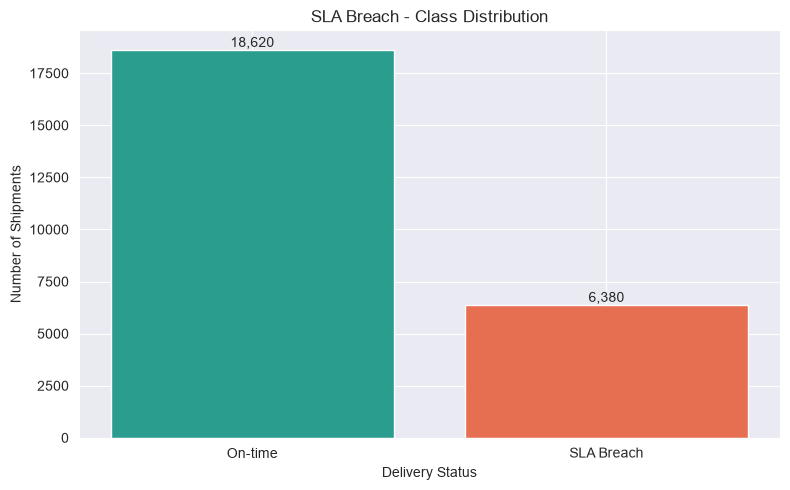

In [83]:
target_counts = classification_df['Is_Delayed_SLA'].value_counts()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ['On-time', 'SLA Breach'],
    target_counts.sort_index().values,
    color=['#2A9D8F', '#E76F51']
)

plt.title('SLA Breach - Class Distribution')
plt.xlabel('Delivery Status')
plt.ylabel('Number of Shipments')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{int(bar.get_height()):,}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

## Preparing X and y

In [84]:
# Separating features and target

X_clf = classification_df.drop(
    columns=['Is_Delayed_SLA']
)

y_clf = classification_df['Is_Delayed_SLA']

print("Feature Dataset Shape:", X_clf.shape)
print("Target Dataset Shape:", y_clf.shape)

print("\nFeature Data Types:")
print(X_clf.dtypes)

Feature Dataset Shape: (25000, 17)
Target Dataset Shape: (25000,)

Feature Data Types:
Delivery_Partner       object
Logistics_Zone         object
Distance_km           float64
Shipment_Mode          object
Weight_kg             float64
Weather_Condition      object
Festival_Peak           int64
Is_COD                  int64
Shipping_Cost_INR     float64
Pickup_Delay_Hours    float64
SLA_Promised_Days       int64
Order_Hour              int32
Order_DayOfWeek         int32
Order_Month             int32
Dispatch_Hour           int32
Dispatch_DayOfWeek      int32
Dispatch_Month          int32
dtype: object


## Chronological Train-Test Split

In [85]:
# Sort records by dispatch timestamp
sorted_index_clf = (
    df.loc[classification_df.index]
    .sort_values('Dispatch_Timestamp')
    .index
)

# Arrange features and target chronologically
X_clf = X_clf.loc[sorted_index_clf]
y_clf = y_clf.loc[sorted_index_clf]

# Define 80:20 split
split_index_clf = int(len(X_clf) * 0.80)

# Training dataset
X_train_clf = X_clf.iloc[:split_index_clf]
y_train_clf = y_clf.iloc[:split_index_clf]

# Testing dataset
X_test_clf = X_clf.iloc[split_index_clf:]
y_test_clf = y_clf.iloc[split_index_clf:]

# Display shapes
print("Training Features:", X_train_clf.shape)
print("Testing Features:", X_test_clf.shape)

print("\nTraining Target:", y_train_clf.shape)
print("Testing Target:", y_test_clf.shape)

# Check date ranges
print("\nTraining Period:")
print(df.loc[X_train_clf.index, 'Dispatch_Timestamp'].min())
print(df.loc[X_train_clf.index, 'Dispatch_Timestamp'].max())

print("\nTesting Period:")
print(df.loc[X_test_clf.index, 'Dispatch_Timestamp'].min())
print(df.loc[X_test_clf.index, 'Dispatch_Timestamp'].max())

Training Features: (20000, 17)
Testing Features: (5000, 17)

Training Target: (20000,)
Testing Target: (5000,)

Training Period:
2026-01-01 02:12:00
2026-08-05 23:00:00

Testing Period:
2026-08-06 03:12:00
2026-09-28 20:48:00


## Preprocessing Pipeline

In [86]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify categorical and numerical columns
categorical_features_clf = (
    X_clf.select_dtypes(include=['object']).columns.tolist()
)

numerical_features_clf = (
    X_clf.select_dtypes(exclude=['object']).columns.tolist()
)

# Create preprocessing pipeline
preprocessor_clf = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features_clf
        ),
        (
            'num',
            StandardScaler(),
            numerical_features_clf
        )
    ]
)

print("Categorical Features:", len(categorical_features_clf))
print("Numerical Features:", len(numerical_features_clf))

print("\nCategorical Columns:")
print(categorical_features_clf)

print("\nNumerical Columns:")
print(numerical_features_clf)

Categorical Features: 4
Numerical Features: 13

Categorical Columns:
['Delivery_Partner', 'Logistics_Zone', 'Shipment_Mode', 'Weather_Condition']

Numerical Columns:
['Distance_km', 'Weight_kg', 'Festival_Peak', 'Is_COD', 'Shipping_Cost_INR', 'Pickup_Delay_Hours', 'SLA_Promised_Days', 'Order_Hour', 'Order_DayOfWeek', 'Order_Month', 'Dispatch_Hour', 'Dispatch_DayOfWeek', 'Dispatch_Month']


## Logistic Regression

In [87]:


lr_clf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor_clf),
        ('model', LogisticRegression(
            class_weight='balanced',
            max_iter=1000,
            random_state=42
        ))
    ]
)

# Train the model
lr_clf_model.fit(X_train_clf, y_train_clf)

print("Logistic Regression Classifier Trained Successfully!")

Logistic Regression Classifier Trained Successfully!


In [88]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Generate predictions
y_pred_lr_clf = lr_clf_model.predict(X_test_clf)

# Generate probability predictions
y_prob_lr_clf = lr_clf_model.predict_proba(X_test_clf)[:, 1]

# Calculate evaluation metrics
precision_lr = precision_score(y_test_clf, y_pred_lr_clf)
recall_lr = recall_score(y_test_clf, y_pred_lr_clf)
f1_lr = f1_score(y_test_clf, y_pred_lr_clf)
roc_auc_lr = roc_auc_score(y_test_clf, y_prob_lr_clf)

print("Logistic Regression Performance")
print("--------------------------------")
print(f"Precision : {precision_lr:.4f}")
print(f"Recall    : {recall_lr:.4f}")
print(f"F1-score  : {f1_lr:.4f}")
print(f"ROC-AUC   : {roc_auc_lr:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_clf, y_pred_lr_clf))

Logistic Regression Performance
--------------------------------
Precision : 0.6718
Recall    : 0.8904
F1-score  : 0.7658
ROC-AUC   : 0.9490

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.86      0.91      3768
           1       0.67      0.89      0.77      1232

    accuracy                           0.87      5000
   macro avg       0.82      0.87      0.84      5000
weighted avg       0.89      0.87      0.87      5000



## Confusion Matrix

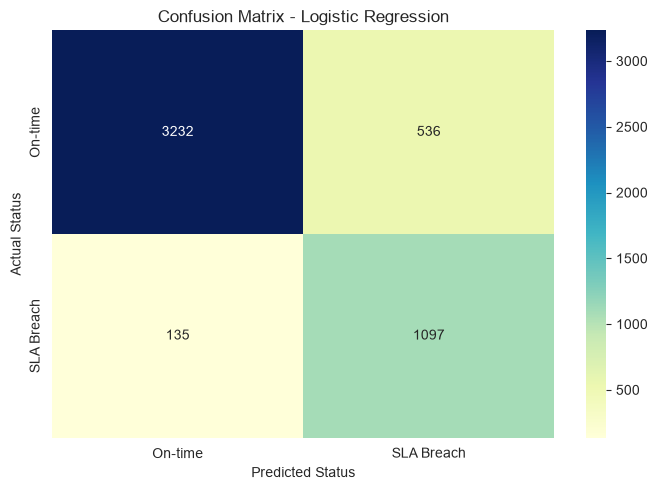

Confusion Matrix:
[[3232  536]
 [ 135 1097]]


In [89]:
# Generating confusion matrix
cm_lr = confusion_matrix(y_test_clf, y_pred_lr_clf)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    xticklabels=['On-time', 'SLA Breach'],
    yticklabels=['On-time', 'SLA Breach']
)

plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted Status')
plt.ylabel('Actual Status')

plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm_lr)

## Decision Tree Classifier

In [91]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

dt_clf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor_clf),
        ('model', DecisionTreeClassifier(
            class_weight='balanced',
            random_state=42
        ))
    ]
)

# Train the model
dt_clf_model.fit(X_train_clf, y_train_clf)

print("Decision Tree Classifier Trained Successfully!")

Decision Tree Classifier Trained Successfully!


## Decision Tree – Model Evaluation

In [92]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Generate predictions
y_pred_dt_clf = dt_clf_model.predict(X_test_clf)

# Generate probability predictions
y_prob_dt_clf = dt_clf_model.predict_proba(X_test_clf)[:, 1]

# Calculate evaluation metrics
precision_dt = precision_score(y_test_clf, y_pred_dt_clf)
recall_dt = recall_score(y_test_clf, y_pred_dt_clf)
f1_dt = f1_score(y_test_clf, y_pred_dt_clf)
roc_auc_dt = roc_auc_score(y_test_clf, y_prob_dt_clf)

print("Decision Tree Classifier Performance")
print("------------------------------------")
print(f"Precision : {precision_dt:.4f}")
print(f"Recall    : {recall_dt:.4f}")
print(f"F1-score  : {f1_dt:.4f}")
print(f"ROC-AUC   : {roc_auc_dt:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_clf, y_pred_dt_clf))

Decision Tree Classifier Performance
------------------------------------
Precision : 0.6896
Recall    : 0.6599
F1-score  : 0.6744
ROC-AUC   : 0.7814

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.90      0.90      3768
           1       0.69      0.66      0.67      1232

    accuracy                           0.84      5000
   macro avg       0.79      0.78      0.79      5000
weighted avg       0.84      0.84      0.84      5000



## Random Forest Classifier

In [93]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_clf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor_clf),
        ('model', RandomForestClassifier(
            n_estimators=200,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train the model
rf_clf_model.fit(X_train_clf, y_train_clf)

print("Random Forest Classifier Trained Successfully!")

Random Forest Classifier Trained Successfully!


In [94]:
# Generate predictions
y_pred_rf_clf = rf_clf_model.predict(X_test_clf)

# Generate probability predictions
y_prob_rf_clf = rf_clf_model.predict_proba(X_test_clf)[:, 1]

# Calculate evaluation metrics
precision_rf = precision_score(y_test_clf, y_pred_rf_clf)
recall_rf = recall_score(y_test_clf, y_pred_rf_clf)
f1_rf = f1_score(y_test_clf, y_pred_rf_clf)
roc_auc_rf = roc_auc_score(y_test_clf, y_prob_rf_clf)

print("Random Forest Classifier Performance")
print("------------------------------------")
print(f"Precision : {precision_rf:.4f}")
print(f"Recall    : {recall_rf:.4f}")
print(f"F1-score  : {f1_rf:.4f}")
print(f"ROC-AUC   : {roc_auc_rf:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_clf, y_pred_rf_clf))

Random Forest Classifier Performance
------------------------------------
Precision : 0.8602
Recall    : 0.6591
F1-score  : 0.7463
ROC-AUC   : 0.9430

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.96      0.93      3768
           1       0.86      0.66      0.75      1232

    accuracy                           0.89      5000
   macro avg       0.88      0.81      0.84      5000
weighted avg       0.89      0.89      0.88      5000



### XGBoost Classifier

In [95]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_clf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor_clf),
        ('model', XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            objective='binary:logistic',
            eval_metric='logloss',
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train the model
xgb_clf_model.fit(X_train_clf, y_train_clf)

print("XGBoost Classifier Trained Successfully!")

XGBoost Classifier Trained Successfully!


In [96]:
# Generate predictions
y_pred_xgb_clf = xgb_clf_model.predict(X_test_clf)

# Generate probability predictions
y_prob_xgb_clf = xgb_clf_model.predict_proba(X_test_clf)[:, 1]

# Calculate evaluation metrics
precision_xgb = precision_score(y_test_clf, y_pred_xgb_clf)
recall_xgb = recall_score(y_test_clf, y_pred_xgb_clf)
f1_xgb = f1_score(y_test_clf, y_pred_xgb_clf)
roc_auc_xgb = roc_auc_score(y_test_clf, y_prob_xgb_clf)

print("XGBoost Classifier Performance")
print("--------------------------------")
print(f"Precision : {precision_xgb:.4f}")
print(f"Recall    : {recall_xgb:.4f}")
print(f"F1-score  : {f1_xgb:.4f}")
print(f"ROC-AUC   : {roc_auc_xgb:.4f}")

print("\nClassification Report:")
print(classification_report(y_test_clf, y_pred_xgb_clf))

XGBoost Classifier Performance
--------------------------------
Precision : 0.8326
Recall    : 0.7305
F1-score  : 0.7782
ROC-AUC   : 0.9504

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.95      0.93      3768
           1       0.83      0.73      0.78      1232

    accuracy                           0.90      5000
   macro avg       0.87      0.84      0.86      5000
weighted avg       0.89      0.90      0.90      5000



,Model,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.6718,0.8904,0.7658,0.9490
1,Decision Tree,0.6896,0.6599,0.6744,0.7814
2,Random Forest,0.8602,0.6591,0.7463,0.9430
3,XGBoost,0.8326,0.7305,0.7782,0.9504


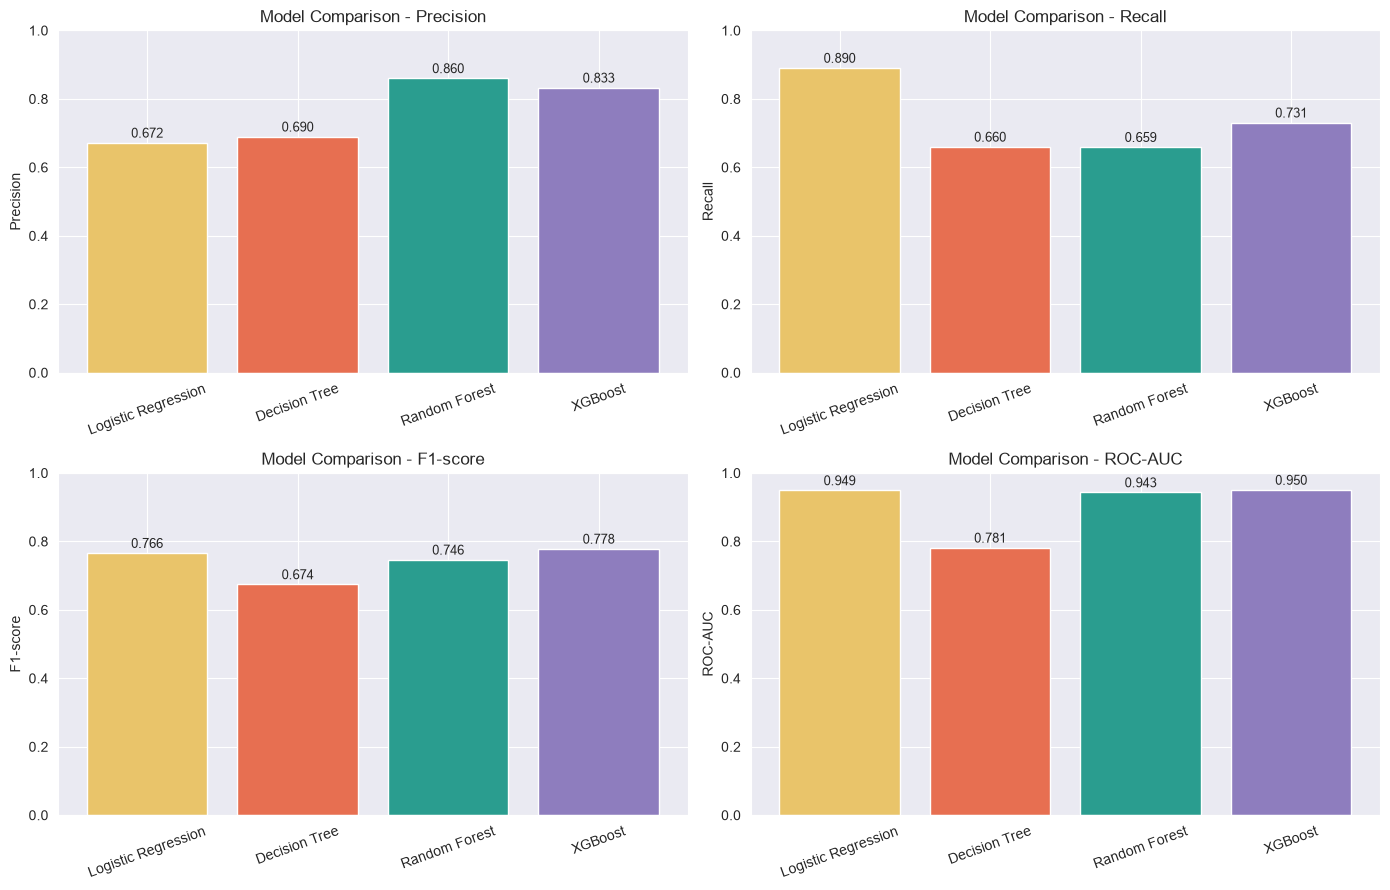

In [97]:
# Create comparison dataframe
classification_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'XGBoost'
    ],
    'Precision': [
        precision_lr,
        precision_dt,
        precision_rf,
        precision_xgb
    ],
    'Recall': [
        recall_lr,
        recall_dt,
        recall_rf,
        recall_xgb
    ],
    'F1-score': [
        f1_lr,
        f1_dt,
        f1_rf,
        f1_xgb
    ],
    'ROC-AUC': [
        roc_auc_lr,
        roc_auc_dt,
        roc_auc_rf,
        roc_auc_xgb
    ]
})

# Display comparison
display(classification_comparison.round(4))

# Plot comparison
metrics = ['Precision', 'Recall', 'F1-score', 'ROC-AUC']

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

colors = ['#E9C46A', '#E76F51', '#2A9D8F', '#8E7DBE']

for ax, metric in zip(axes.flat, metrics):
    bars = ax.bar(
        classification_comparison['Model'],
        classification_comparison[metric],
        color=colors
    )

    ax.set_title(f'Model Comparison - {metric}')
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=20)

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.015,
            f'{bar.get_height():.3f}',
            ha='center',
            fontsize=9
        )

plt.tight_layout()
plt.show()

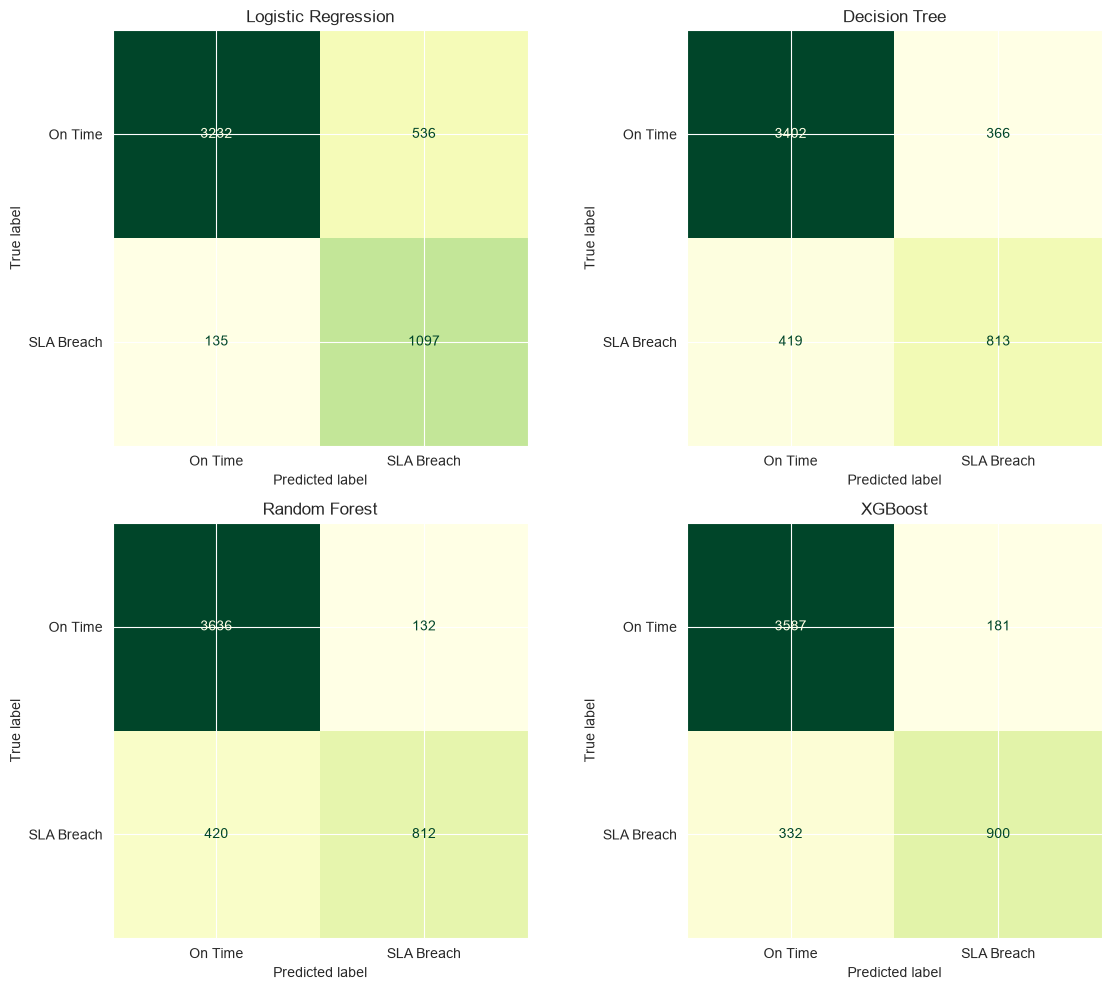

In [98]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

models = {
    'Logistic Regression': y_pred_lr_clf,
    'Decision Tree': y_pred_dt_clf,
    'Random Forest': y_pred_rf_clf,
    'XGBoost': y_pred_xgb_clf
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, predictions) in zip(axes.flat, models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test_clf,
        predictions,
        display_labels=['On Time', 'SLA Breach'],
        cmap='YlGn',
        colorbar=False,
        ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

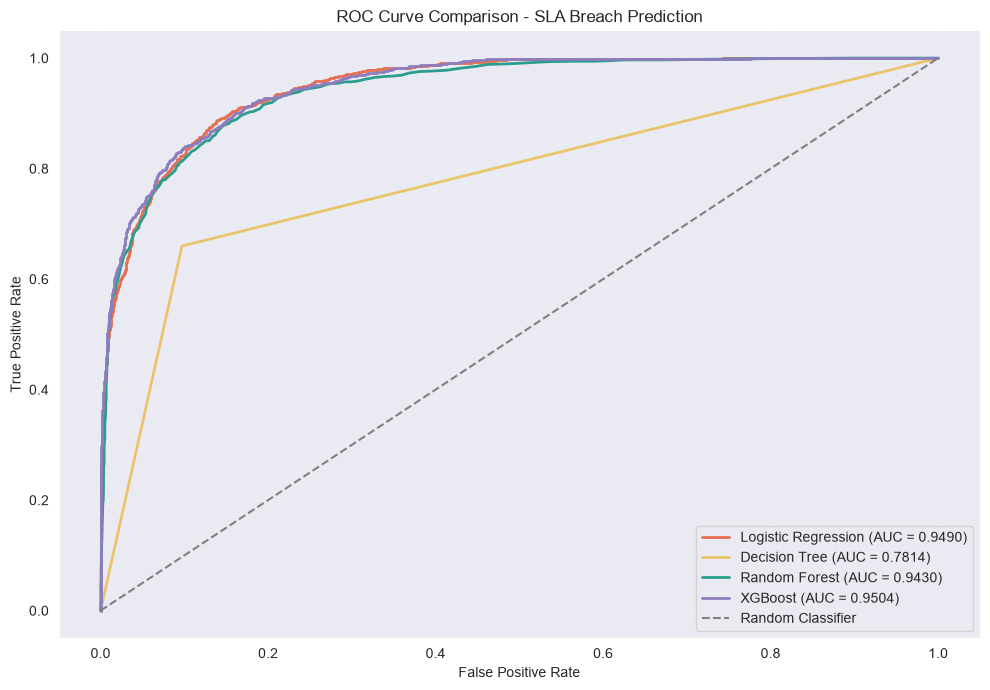

In [99]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Predicted probabilities for each model
model_probabilities = {
    'Logistic Regression': y_prob_lr_clf,
    'Decision Tree': y_prob_dt_clf,
    'Random Forest': y_prob_rf_clf,
    'XGBoost': y_prob_xgb_clf
}

plt.figure(figsize=(10, 7))

colors = ['#E76F51', '#E9C46A', '#2A9D8F', '#8E7DBE']

for (model_name, probabilities), color in zip(
    model_probabilities.items(), colors
):
    fpr, tpr, thresholds = roc_curve(y_test_clf, probabilities)
    roc_auc_value = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f'{model_name} (AUC = {roc_auc_value:.4f})',
        color=color,
        linewidth=2
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison - SLA Breach Prediction')

plt.legend(loc='lower right')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Model 2: SLA Breach Prediction – Classification

## 1. Business Objective

The objective of this classification model is to predict whether a shipment is likely to breach its promised Service Level Agreement (SLA).

An early warning system can help logistics operations teams identify potentially delayed shipments at the dispatch stage and take preventive actions, such as prioritising shipments, monitoring high-risk routes, or coordinating with delivery partners.

**Prediction Point:** At the time of dispatch.

**Target Variable:** `Is_Delayed_SLA`

* `0` – Shipment delivered within the promised SLA.
* `1` – Shipment breached the promised SLA.

The model is designed to identify potential SLA breaches using information available at dispatch time.

---

## 2. Dataset Preparation

A separate classification dataset was created from the cleaned dataset.

Date and time components were extracted from the order and dispatch timestamps to capture temporal patterns.

### Dataset Summary

| Description      |          Value |
| ---------------- | -------------: |
| Total Records    |         25,000 |
| Total Features   |             17 |
| Target Variable  | Is_Delayed_SLA |
| Training Records |         20,000 |
| Testing Records  |          5,000 |
| Missing Values   |              0 |

### Target Distribution

| Class | Description      | Records | Percentage |
| ----- | ---------------- | ------: | ---------: |
| 0     | On-Time Delivery |  18,620 |     74.48% |
| 1     | SLA Breach       |   6,380 |     25.52% |

The target variable showed moderate class imbalance, with approximately 25.52% of shipments experiencing SLA breaches.

Since the imbalance was not extremely severe, SMOTE and undersampling were not applied initially.

---

## 3. Feature Selection

The model uses 17 independent variables that are assumed to be available at the dispatch stage.

### Selected Features

**Categorical Features:**

* Delivery_Partner
* Logistics_Zone
* Shipment_Mode
* Weather_Condition

**Numerical Features:**

* Distance_km
* Weight_kg
* Festival_Peak
* Is_COD
* Shipping_Cost_INR
* Pickup_Delay_Hours
* SLA_Promised_Days
* Order_Hour
* Order_DayOfWeek
* Order_Month
* Dispatch_Hour
* Dispatch_DayOfWeek
* Dispatch_Month

### Excluded Features

The following columns were excluded to prevent target leakage:

* Actual_Delivery_Days
* Transit_Time_Hours
* Expected_Delivery_Timestamp
* Expected_Delivery_Date
* Order_ID
* Is_Delayed_SLA from the input features

Actual delivery information and SLA outcomes are only known after shipment completion and therefore cannot be used for a prediction made at dispatch.

SLA_Promised_Days was retained because it is known at dispatch and directly defines the delivery commitment.

---

## 4. Data Preprocessing

A ColumnTransformer was used to preprocess categorical and numerical variables.

**Categorical Features:**

* One-Hot Encoding was applied.
* `handle_unknown='ignore'` was used to handle previously unseen categories.

**Numerical Features:**

* StandardScaler was applied to standardise numerical variables.

All preprocessing steps were incorporated into Scikit-learn Pipelines to ensure that transformations were fitted only on training data and then applied to testing data.

This helped prevent data leakage during model training and evaluation.

---

## 5. Train-Test Split

A chronological 80:20 split was implemented using the dispatch timestamp.

| Dataset      | Records | Period                        |
| ------------ | ------: | ----------------------------- |
| Training Set |  20,000 | January 1 – August 5, 2026    |
| Testing Set  |   5,000 | August 6 – September 28, 2026 |

A chronological split was preferred over a random split because it better represents a real-world scenario where historical shipments are used to predict future shipment outcomes.

The models were trained on earlier shipment records and evaluated on later records.

---

## 6. Model Development

Four classification algorithms were trained and evaluated.

### Model 1: Logistic Regression

Logistic Regression was implemented as a baseline classification model.

* `class_weight='balanced'` was applied to account for class imbalance.
* `max_iter=1000` was used to support convergence.

### Model 2: Decision Tree Classifier

A Decision Tree was implemented to capture nonlinear relationships and decision rules.

* `class_weight='balanced'` was applied.
* `random_state=42` was used for reproducibility.

### Model 3: Random Forest Classifier

Random Forest was implemented using an ensemble of decision trees.

* Number of estimators: 200
* `class_weight='balanced'`
* `random_state=42`
* `n_jobs=-1`

### Model 4: XGBoost Classifier

XGBoost was implemented as a gradient-boosting classification model.

**Hyperparameters:**

* Number of estimators: 300
* Learning rate: 0.05
* Maximum depth: 6
* Subsample: 0.8
* Column sampling by tree: 0.8
* Objective: Binary Logistic
* Evaluation metric: Log Loss

The initial XGBoost model was trained without applying `scale_pos_weight`.

---

## 7. Model Evaluation

The models were evaluated using the following classification metrics:

**Precision:** Measures how many shipments predicted as SLA breaches were actually delayed.

**Recall:** Measures how many actual SLA breaches were successfully identified by the model.

**F1-score:** Provides a balance between Precision and Recall.

**ROC-AUC:** Measures the model's ability to distinguish between on-time and delayed shipments across different classification thresholds.

### Model Performance Comparison

| Model               |  Precision |     Recall |   F1-score |    ROC-AUC |
| ------------------- | ---------: | ---------: | ---------: | ---------: |
| Logistic Regression |     0.6718 | **0.8904** |     0.7658 |     0.9490 |
| Decision Tree       |     0.6896 |     0.6599 |     0.6744 |     0.7814 |
| Random Forest       | **0.8602** |     0.6591 |     0.7463 |     0.9430 |
| XGBoost             |     0.8326 |     0.7305 | **0.7782** | **0.9504** |

### Key Observations

**Logistic Regression**

* Achieved the highest Recall of 89.04%.
* Identified the largest proportion of actual SLA breaches.
* Suitable when minimising missed SLA breaches is the primary business objective.

**Decision Tree**

* Achieved the lowest F1-score and ROC-AUC.
* Its overall classification performance was weaker than the other models.

**Random Forest**

* Achieved the highest Precision of 86.02%.
* Its breach predictions were more reliable, but its Recall was comparatively low.
* Missed a larger proportion of actual SLA breaches.

**XGBoost**

* Achieved the highest F1-score of 77.82%.
* Achieved the highest ROC-AUC of 95.04%.
* Provided the best overall balance between Precision and Recall among the four tested models.

---

## 8. Confusion Matrix Analysis

Confusion matrices were generated to compare the classification outcomes of all four models.

The four outcomes are:

* **True Positive (TP):** An actual SLA breach correctly predicted as a breach.
* **True Negative (TN):** An on-time shipment correctly predicted as on time.
* **False Positive (FP):** An on-time shipment incorrectly predicted as a breach.
* **False Negative (FN):** An actual SLA breach incorrectly predicted as on time.

For Logistic Regression, the confusion matrix was:

|                   | Predicted On-Time | Predicted SLA Breach |
| ----------------- | ----------------: | -------------------: |
| Actual On-Time    |             3,232 |                  536 |
| Actual SLA Breach |               135 |                1,097 |

Logistic Regression successfully identified 1,097 out of 1,232 actual SLA breaches in the test dataset.

However, it also generated 536 false-positive alerts.

Confusion matrices for all four models were visualised to compare their classification behaviour.

---

## 9. ROC Curve Comparison

ROC curves were plotted for all four classification models using their predicted probabilities.

The ROC-AUC results were:

* Logistic Regression: 0.9490
* Decision Tree: 0.7814
* Random Forest: 0.9430
* XGBoost: 0.9504

XGBoost achieved the highest ROC-AUC, narrowly outperforming Logistic Regression.

This indicates that XGBoost demonstrated the strongest overall ability to distinguish between on-time shipments and SLA breaches across different classification thresholds.

---

## 10. Final Model Selection

Based on the evaluation results, **XGBoost was selected as the primary candidate model for SLA breach prediction**.

The selection was based on:

1. Highest F1-score among the four models.
2. Highest ROC-AUC.
3. Strong Precision and Recall balance.
4. Better overall classification performance than the Decision Tree and Random Forest models.

However, Logistic Regression achieved a significantly higher Recall of 89.04%, compared with XGBoost's 73.05%.

In an operational logistics environment, missing an actual SLA breach may have a greater business impact than generating an unnecessary alert.

Therefore, Logistic Regression could be preferable when the primary objective is to identify as many potential SLA breaches as possible.

The final model choice should depend on the business cost of false positives versus false negatives. Classification threshold tuning and further validation would be required before production deployment.

---

## 11. Business Applications

An SLA breach prediction system can support logistics operations in several ways:

* **Early Warning System:** Identify shipments with a higher probability of breaching their promised SLA.
* **Shipment Prioritisation:** Help operations teams prioritise potentially delayed shipments.
* **Operational Monitoring:** Monitor high-risk shipments across delivery partners and logistics zones.
* **Resource Allocation:** Support better allocation of operational resources during festival periods and adverse weather conditions.
* **Customer Communication:** Enable proactive communication with customers when a shipment is identified as high risk.
* **Performance Monitoring:** Support continuous monitoring of SLA performance.

---

## 12. Limitations and Considerations

* The dataset is synthetic and does not represent actual logistics operations.
* Model performance may differ significantly on real-world shipment data.
* Weather information is assumed to be available at dispatch; this assumption must be validated in a real deployment.
* Shipping cost is also assumed to be available at the prediction stage.
* The chronological test dataset covers a limited future period, so additional temporal validation is recommended.
* Model performance depends on the quality and consistency of the input data.
* Classification thresholds have not been optimised for specific business costs.
* High predictive performance does not establish a causal relationship between a feature and SLA breaches.

---

## 13. Final Conclusion

The SLA Breach Prediction model successfully demonstrated how machine learning classification algorithms can be used to identify shipments at risk of missing their promised delivery timelines.

Four classification algorithms were developed and evaluated using a chronological train-test split.

Among the tested models, XGBoost achieved the best overall balance between Precision and Recall, with an F1-score of 77.82% and ROC-AUC of 95.04%.

Logistic Regression achieved the highest Recall of 89.04%, making it a strong alternative when identifying the maximum number of potential SLA breaches is the primary objective.

This model demonstrates the potential of predictive analytics to support proactive shipment monitoring, improve operational visibility, and help logistics teams take preventive action before SLA commitments are missed.

**Project Status: Model Development and Evaluation Completed.**


In [101]:
from sqlalchemy import create_engine

username = "postgres"
password = "Papu1993"
host = "localhost"
port = "5432"
database = "Logistics_Analysis"

engine = create_engine(
    f"postgresql+psycopg2://{username}:{password}@{host}:{port}/{database}"
)

df.to_sql(
    "logistics_shipments",
    engine,
    if_exists="replace",
    index=False
)
print("Data successfully loaded into table: logistics_shipments")

Data successfully loaded into table: logistics_shipments
